### Capacitação em Processamento Digital de Sinais - VIRTUS CC
Orientador: Edson Porto

Aluno: Lucas de Souza Salvino


### Relatório 2: Transformadas Discretas

Objetivos:
1. Implementar DFT/IDFT manualmente e verificar suas propriedades (ver tabela de propriedades nos slides). 

2. Implementar a convolução linear a partir da convolução circular utilizando a DFT/IDFT.

3. Implementar os métodos overlap-and-add e overlap and save para o cálculo de convoluções lineares via DFT/IDFT.

4. Implementar o algoritmo da FFT e comparar tempo de execução e resultado com a DFT




# 1. Transformada Discreta de Fourier (DFT) e sua Inversa (IDFT)

A **Transformada Discreta de Fourier (DFT)** faz o mapeamento de um sinal de comprimento finito que depende de uma variável discreta de tempo $n$ em uma transformada que depende de uma variável discreta de frequência $k$, tomando $N$ amostras uniformemente espaçadas em $\omega_k = \frac{2\pi}{N}k$. A **IDFT** permite recuperar o sinal no tempo discreto $x[n]$ a partir de seus coeficientes espectrais $X[k]$.

Definindo $W_N = e^{-j\frac{2\pi}{N}}$:

* **DFT Direta:**
$$X[k] = \frac{1}{\sqrt{N}} \sum_{n=0}^{N-1} x[n] W_N^{kn} = \frac{1}{\sqrt{N}} \sum_{n=0}^{N-1} x[n] e^{-j\frac{2\pi}{N}kn}, \quad 0 \le k \le N-1$$

* **IDFT (Transformada Inversa):**
$$x[n] = \frac{1}{\sqrt{N}} \sum_{k=0}^{N-1} X[k] W_N^{-kn} = \frac{1}{\sqrt{N}} \sum_{k=0}^{N-1} X[k] e^{j\frac{2\pi}{N}kn}, \quad 0 \le n \le N-1$$


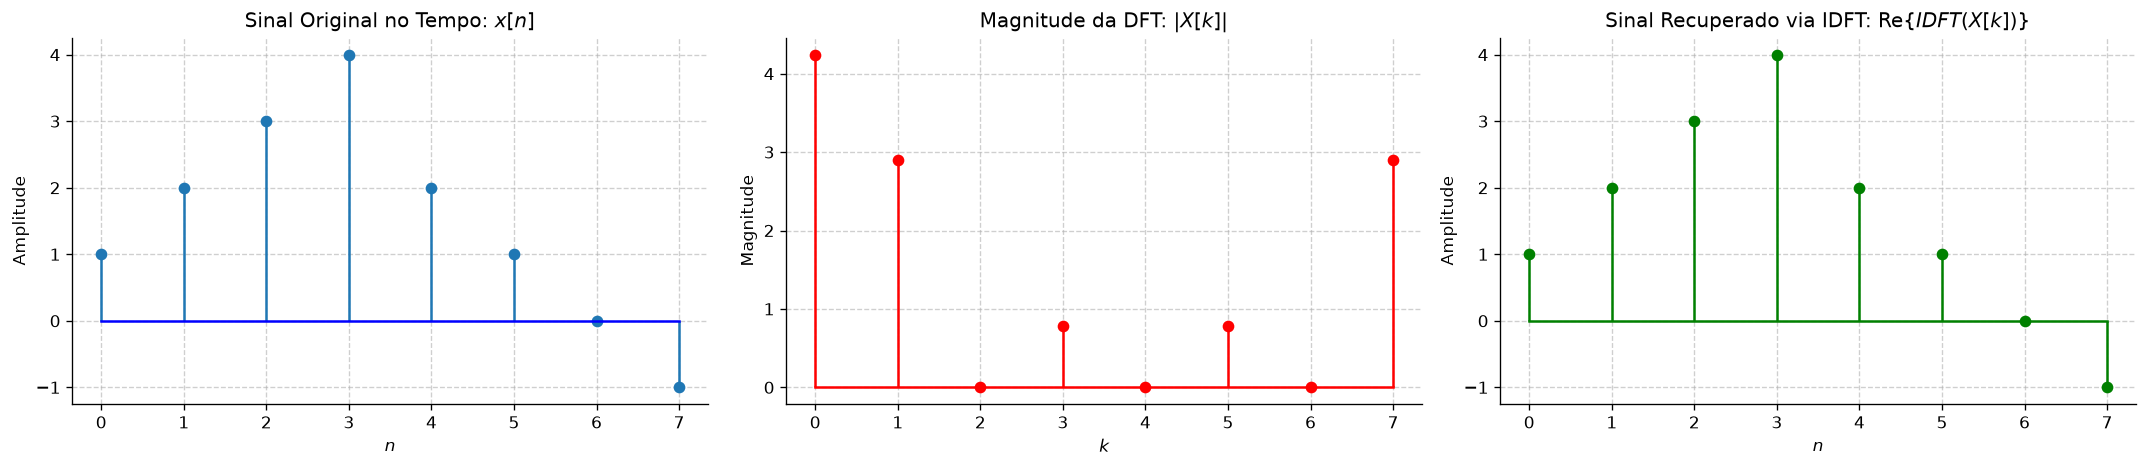

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np

def DFT(x):
    """Calcula a DFT manualmente através de laços aninhados."""
    N = len(x)
    X = np.zeros(N, dtype=complex)
    for k in range(N):
        for n in range(N):
            X[k] += x[n] * np.exp(-1j * (2 * np.pi / N) * k * n)
    return X / np.sqrt(N)

def IDFT(X):
    """Calcula a IDFT manualmente através de laços aninhados."""
    N = len(X)
    x = np.zeros(N, dtype=complex)
    for n in range(N):
        for k in range(N):
            x[n] += X[k] * np.exp(1j * (2 * np.pi / N) * k * n)
    return x / np.sqrt(N)

# Sinal de teste de comprimento N = 8
x_orig = np.array([1.0, 2.0, 3.0, 4.0, 2.0, 1.0, 0.0, -1.0])
n_idx = np.arange(len(x_orig))

X_k = DFT(x_orig)
x_rec = np.real(IDFT(X_k))

# Visualização Gráfica
fig, axs = plt.subplots(1, 3, figsize=(18, 4))

axs[0].stem(n_idx, x_orig, basefmt="b-")
axs[0].set_title(r"Sinal Original no Tempo: $x[n]$")
axs[0].set_xlabel(r"$n$")
axs[0].set_ylabel("Amplitude")
axs[0].grid(True, linestyle="--", alpha=0.6)

axs[1].stem(n_idx, np.abs(X_k), linefmt="r-", markerfmt="ro", basefmt="r-")
axs[1].set_title(r"Magnitude da DFT: $\vert{}X[k]\vert{}$")
axs[1].set_xlabel(r"$k$")
axs[1].set_ylabel("Magnitude")
axs[1].grid(True, linestyle="--", alpha=0.6)

axs[2].stem(n_idx, x_rec, linefmt="g-", markerfmt="go", basefmt="g-")
axs[2].set_title(r"Sinal Recuperado via IDFT: $\mathrm{Re}\{IDFT(X[k])\}$")
axs[2].set_xlabel(r"$n$")
axs[2].set_ylabel("Amplitude")
axs[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

plt.show()

# Validação DFT e IDFT usando a biblioteca numpy

In [ ]:
X_k_numpy = np.fft.fft(x_orig, norm="ortho")
x_rec_numpy = np.fft.ifft(X_k_numpy, norm="ortho")


print("=" * 90)
print(f"{'Índice (k)':<12} | {'DFT Manual':<35} | {'DFT NumPy'}")
print("-" * 90)
for i in range(len(X_k)):
    # Utilizando np.round para facilitar a visualização de números complexos
    print(f"{i:<12} | {np.round(X_k[i], 4)!s:<35} | {np.round(X_k_numpy[i], 4)}")

# Comparação da IDFT lado a lado
print("\n" + "=" * 90)
print(f"{'Índice (n)':<12} | {'IDFT Manual (Parte Real)':<35} | {'IDFT NumPy (Parte Real)'}")
print("-" * 90)
for i in range(len(x_rec)):
    print(f"{i:<12} | {np.round(x_rec[i], 4):<35} | {np.round(np.real(x_rec_numpy[i]), 4)}")
print("=" * 90)






Índice (k)   | DFT Manual                          | DFT NumPy
------------------------------------------------------------------------------------------
0            | (4.2426+0j)                         | (4.2426+0j)
1            | (-1.3536-2.5607j)                   | (-1.3536-2.5607j)
2            | 0j                                  | 0j
3            | (0.6464-0.4393j)                    | (0.6464-0.4393j)
4            | 0j                                  | 0j
5            | (0.6464+0.4393j)                    | (0.6464+0.4393j)
6            | (-0+0j)                             | 0j
7            | (-1.3536+2.5607j)                   | (-1.3536+2.5607j)

Índice (n)   | IDFT Manual (Parte Real)            | IDFT NumPy (Parte Real)
------------------------------------------------------------------------------------------
0            | 1.0                                 | 1.0
1            | 2.0                                 | 2.0
2            | 3.0                              

# Verificação Gráfica das Propriedades da DFT

Como a DFT equivale à representação de um sinal periódico de período $N$, todas as operações de deslocamento e reversão ocorrem de forma **circular** (módulo $N$). Nos gráficos a seguir, sobrepomos o resultado da **DFT da operação no tempo** (marcadores azuis grandes `o`) com a **expressão teórica no domínio da frequência** (marcadores vermelhos `x`). A sobreposição exata comprova cada propriedade.

1. **Linearidade:** $\alpha x_1[n] + \beta x_2[n] \longleftrightarrow \alpha X_1[k] + \beta X_2[k]$
2. **Deslocamento no tempo:** $x[(n - n_0) \text{ mod } N] \longleftrightarrow e^{-j 2\pi k n_0 / N} X[k]$ (Não altera a magnitude $\vert{}X[k]\vert{}$, mas adiciona um deslocamento linear na fase).
3. **Deslocamento na frequência:** $x[n] e^{j 2\pi k_0 n / N} \longleftrightarrow X[(k - k_0) \text{ mod } N]$.

### O que é o deslocamento "mod N" (Módulo N)?

Na matemática, a operação **mod N** calcula o resto da divisão inteira de um número por $N$. O resultado dessa operação será obrigatoriamente sempre um valor contido entre $0$ e $N-1$. 

Na Transformada Discreta de Fourier (DFT), lidamos com sinais que têm um tamanho fixo $N$. A DFT enxerga esse vetor como um ciclo que se repete infinitamente, colando o final do vetor no começo dele. 
    
Se você tenta deslocar as amostras para a direita e uma delas ultrapassa o limite do vetor, a operação modular entra em cena para fechar o ciclo. A amostra não "cai" para fora do vetor e se perde; ela dá a volta e reaparece no início. Esse movimento de dar a volta no próprio vetor é o que a teoria chama de **deslocamento circular**.

PROPRIEDADE 1: LINEARIDADE
Conclusão: Como o círculo azul cai exatamente no meio do 'x' vermelho em todos os pontos,
tanto na parte real quanto na imaginária, provamos que calcular a DFT da soma é o
mesmo que somar as DFTs.


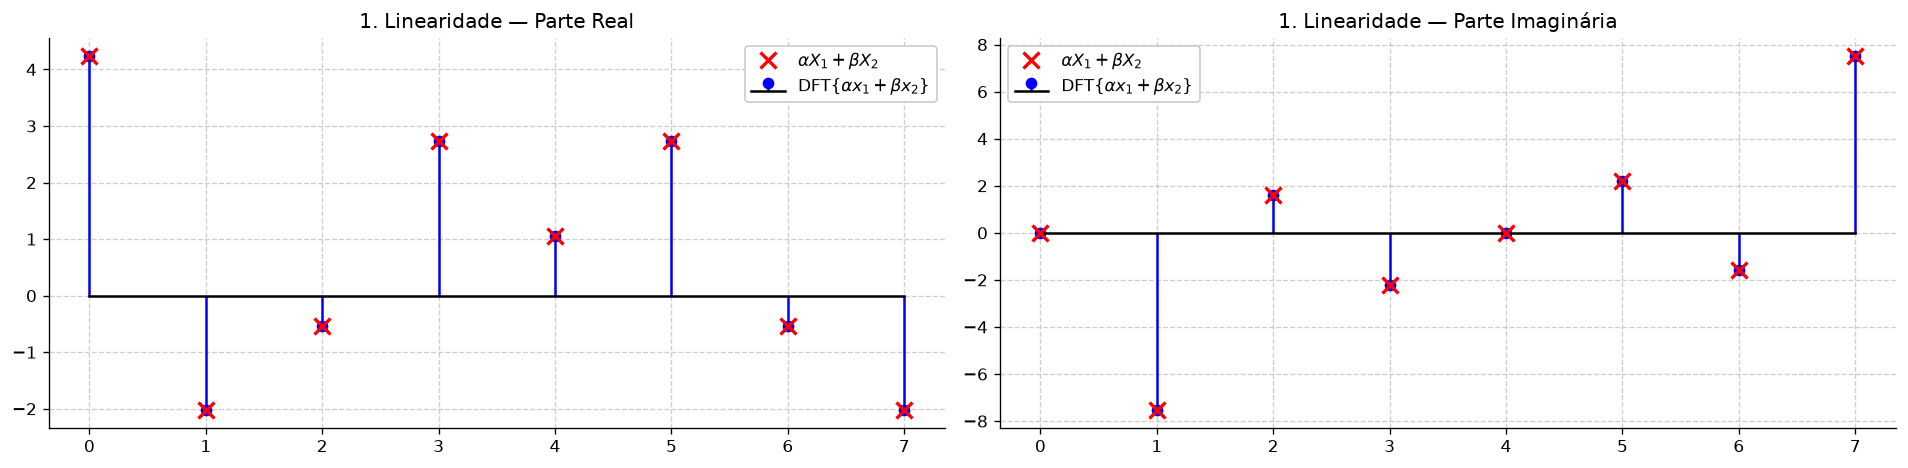


PROPRIEDADE 2: DESLOCAMENTO CIRCULAR NO TEMPO (n0 = 3)
Conclusão: O gráfico da esquerda mostra que o sinal deslocado não se perde ao ultrapassar o
limite do vetor; ele dá a volta e reaparece no início devido ao deslocamento circular.
O gráfico da direita mostra que um deslocamento no tempo não altera o módulo da frequência,
mas rotaciona a sua fase. A correspondência exata prova a propriedade.


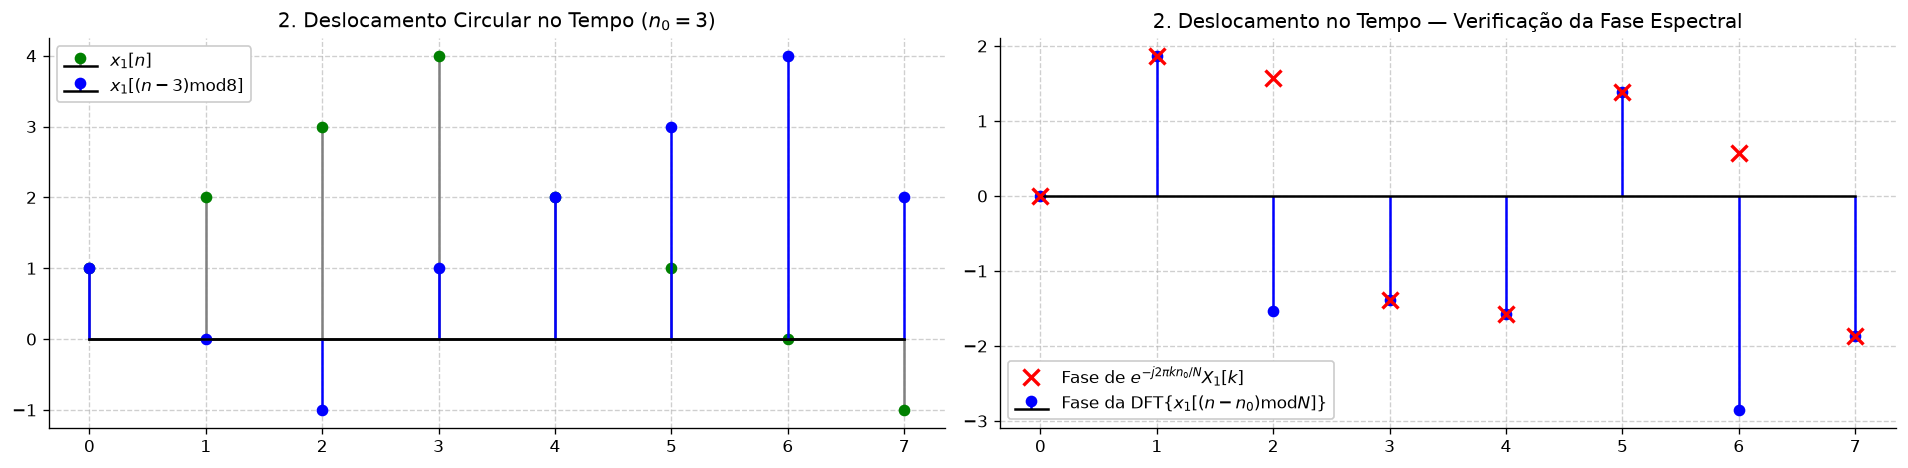


PROPRIEDADE 3: DESLOCAMENTO CIRCULAR NA FREQUÊNCIA (k0 = 2)
Conclusão: O Teorema da Modulação indica que quando multiplicamos o sinal no tempo por uma
exponencial complexa, o espectro sofre um deslocamento no domínio da frequência.
O espectro inteiro andou k0=2 casas para a direita de forma circular, e o pico que estava
em k=7 deu a volta e foi parar em k=1. A equivalência atesta o comportamento.


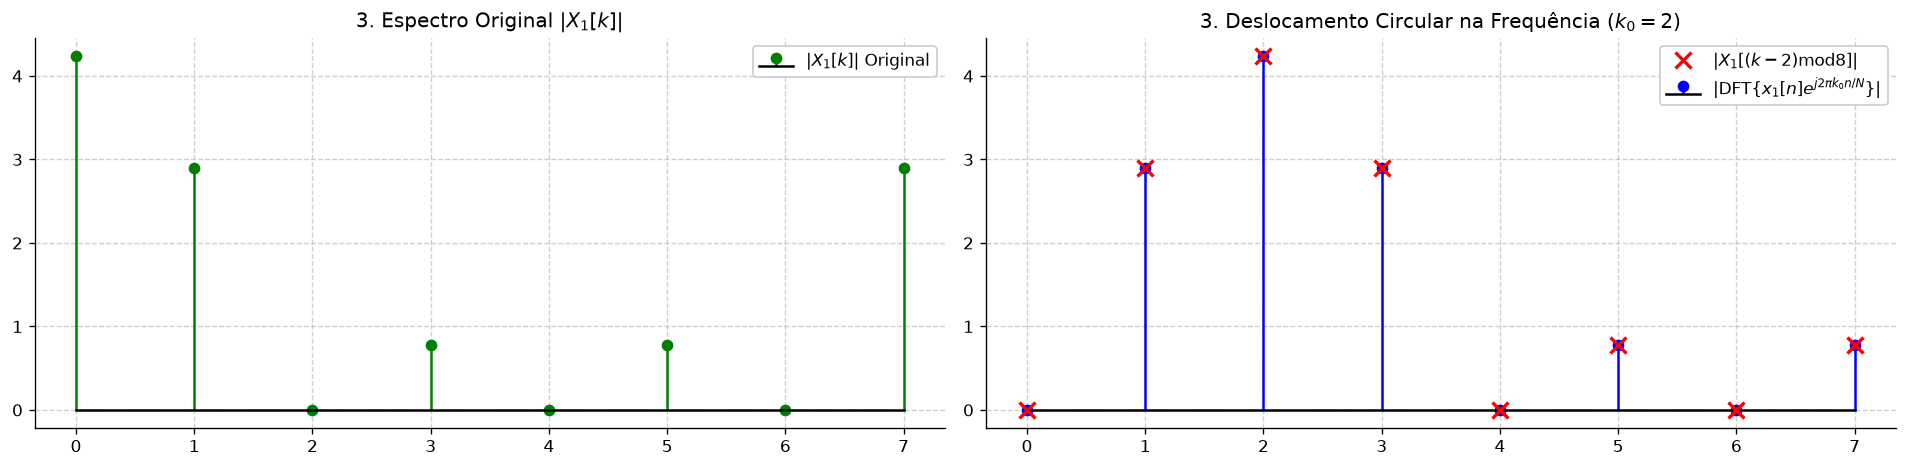

In [60]:
N = 8
n = np.arange(N)
k = np.arange(N)

x1 = np.array([1.0, 2.0, 3.0, 4.0, 2.0, 1.0, 0.0, -1.0])
x2 = np.array([0.0, 1.0, 0.0, -1.0, 2.0, 3.0, 1.0, 2.0])
X1 = DFT(x1)
X2 = DFT(x2)

# =====================================================================
# 1. Linearidade
# =====================================================================
alfa, beta = 2.0, -1.5
esq_lin = DFT(alfa * x1 + beta * x2)
dir_lin = alfa * X1 + beta * X2

print("="*90)
print("PROPRIEDADE 1: LINEARIDADE")
print("Conclusão: Como o círculo azul cai exatamente no meio do 'x' vermelho em todos os pontos,")
print("tanto na parte real quanto na imaginária, provamos que calcular a DFT da soma é o")
print("mesmo que somar as DFTs.")
print("="*90)

fig1, axs1 = plt.subplots(1, 2, figsize=(16, 4))
axs1[0].stem(k, np.real(esq_lin), linefmt="b-", markerfmt="bo", basefmt="k-", label="DFT{$\\alpha x_1 + \\beta x_2$}")
axs1[0].plot(k, np.real(dir_lin), "rx", markersize=10, markeredgewidth=2, label="$\\alpha X_1 + \\beta X_2$")
axs1[0].set_title("1. Linearidade — Parte Real")
axs1[0].legend()
axs1[0].grid(True, linestyle="--", alpha=0.6)

axs1[1].stem(k, np.imag(esq_lin), linefmt="b-", markerfmt="bo", basefmt="k-", label="DFT{$\\alpha x_1 + \\beta x_2$}")
axs1[1].plot(k, np.imag(dir_lin), "rx", markersize=10, markeredgewidth=2, label="$\\alpha X_1 + \\beta X_2$")
axs1[1].set_title("1. Linearidade — Parte Imaginária")
axs1[1].legend()
axs1[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# =====================================================================
# 2. Deslocamento no tempo (n0 = 3)
# =====================================================================
n0 = 3
x1_desl_t = np.array([x1[(i - n0) % N] for i in range(N)])
esq_desl_t = DFT(x1_desl_t)
dir_desl_t = np.exp(-1j * 2 * np.pi * k * n0 / N) * X1

print("\n" + "="*90)
print("PROPRIEDADE 2: DESLOCAMENTO CIRCULAR NO TEMPO (n0 = 3)")
print("Conclusão: O gráfico da esquerda mostra que o sinal deslocado não se perde ao ultrapassar o")
print("limite do vetor; ele dá a volta e reaparece no início devido ao deslocamento circular.")
print("O gráfico da direita mostra que um deslocamento no tempo não altera o módulo da frequência,")
print("mas rotaciona a sua fase. A correspondência exata prova a propriedade.")
print("="*90)

fig2, axs2 = plt.subplots(1, 2, figsize=(16, 4))
axs2[0].stem(n, x1, linefmt="gray", markerfmt="go", basefmt="k-", label="$x_1[n]$")
axs2[0].stem(n, x1_desl_t, linefmt="b-", markerfmt="bo", basefmt="k-", label=f"$x_1[(n-{n0}) \\mathrm{{ mod }} {N}]$")
axs2[0].set_title("2. Deslocamento Circular no Tempo ($n_0 = 3$)")
axs2[0].legend()
axs2[0].grid(True, linestyle="--", alpha=0.6)

axs2[1].stem(k, np.angle(esq_desl_t), linefmt="b-", markerfmt="bo", basefmt="k-", label="Fase da DFT{$x_1[(n-n_0)\\mathrm{ mod }N]$}")
axs2[1].plot(k, np.angle(dir_desl_t), "rx", markersize=10, markeredgewidth=2, label="Fase de $e^{-j2\\pi k n_0/N}X_1[k]$")
axs2[1].set_title("2. Deslocamento no Tempo — Verificação da Fase Espectral")
axs2[1].legend()
axs2[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# =====================================================================
# 3. Deslocamento na Frequência (k0 = 2)
# =====================================================================
k0 = 2
x1_mod = x1 * np.exp(1j * 2 * np.pi * k0 * n / N)
esq_desl_f = DFT(x1_mod)
dir_desl_f = np.array([X1[(i - k0) % N] for i in range(N)])

print("\n" + "="*90)
print("PROPRIEDADE 3: DESLOCAMENTO CIRCULAR NA FREQUÊNCIA (k0 = 2)")
print("Conclusão: O Teorema da Modulação indica que quando multiplicamos o sinal no tempo por uma")
print("exponencial complexa, o espectro sofre um deslocamento no domínio da frequência.")
print("O espectro inteiro andou k0=2 casas para a direita de forma circular, e o pico que estava")
print("em k=7 deu a volta e foi parar em k=1. A equivalência atesta o comportamento.")
print("="*90)

fig3, axs3 = plt.subplots(1, 2, figsize=(16, 4))
axs3[0].stem(k, np.abs(X1), linefmt="g-", markerfmt="go", basefmt="k-", label="$|X_1[k]|$ Original")
axs3[0].set_title("3. Espectro Original $|X_1[k]|$")
axs3[0].legend()
axs3[0].grid(True, linestyle="--", alpha=0.6)

axs3[1].stem(k, np.abs(esq_desl_f), linefmt="b-", markerfmt="bo", basefmt="k-", label="|DFT{$x_1[n]e^{j2\\pi k_0 n/N}$}|")
axs3[1].plot(k, np.abs(dir_desl_f), "rx", markersize=10, markeredgewidth=2, label=f"$|X_1[(k-{k0})\\mathrm{{ mod }}{N}]|$")
axs3[1].set_title(f"3. Deslocamento Circular na Frequência ($k_0 = {k0}$)")
axs3[1].legend()
axs3[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### Reversão Temporal, Conjugação Complexa, Convolução Circular e Multiplicação

4. **Reversão temporal:** $x[(-n) \text{ mod } N] \longleftrightarrow X[(-k) \text{ mod } N]$
5. **Conjugação complexa:** $x^*[n] \longleftrightarrow X^*[(-k) \text{ mod } N]$
6. **Convolução circular no tempo:** $x[n] \circledast h[n] \longleftrightarrow \sqrt{N} X[k] H[k]$
7. **Multiplicação ponto a ponto:** $x[n] h[n] \longleftrightarrow \frac{1}{\sqrt{N}} (X[k] \circledast H[k])$

PROPRIEDADE 4: REVERSÃO TEMPORAL
Conclusão: Reverter um sinal no tempo de forma circular equivale a reverter o seu
espectro na frequência também de forma circular. O gráfico abaixo compara as partes
imaginárias de ambos os lados da equação. A sobreposição exata dos marcadores
azuis e vermelhos comprova a propriedade.


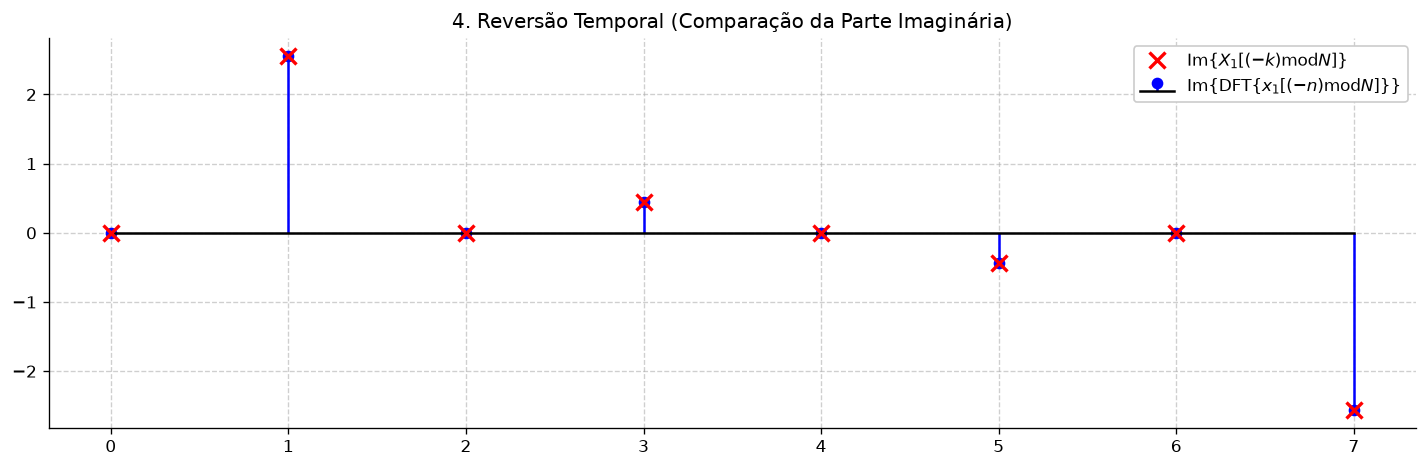


PROPRIEDADE 5: CONJUGAÇÃO COMPLEXA
Conclusão: Aplicar a conjugação complexa em um sinal no domínio do tempo resulta em
um espectro que é conjugado e também revertido circularmente. O gráfico abaixo compara o
módulo (magnitude) de ambos os lados. A coincidência total demonstra a validade da propriedade.


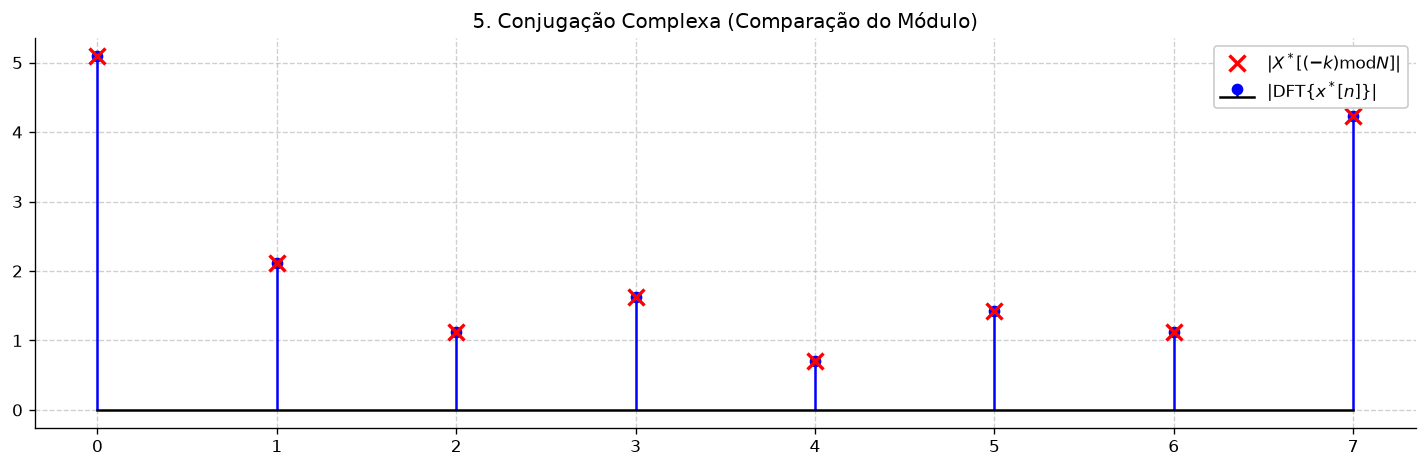


PROPRIEDADE 6: CONVOLUÇÃO CIRCULAR NO TEMPO
Conclusão: Esta é uma das propriedades MAIS IMPORTANTES do processamento de sinais!
Fazer uma convolução circular no domínio do tempo é matematicamente equivalente a apenas
multiplicar os sinais ponto a ponto no domínio da frequência (escalados por √N na nossa convenção).
A sobreposição perfeita dos módulos prova esse poderoso teorema da convolução.


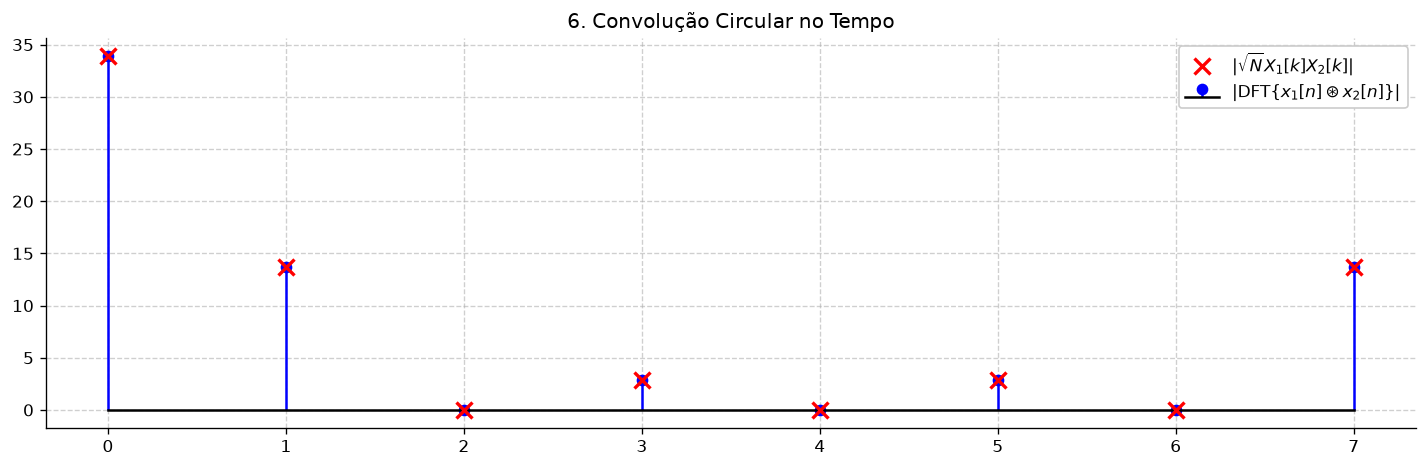


PROPRIEDADE 7: MULTIPLICAÇÃO PONTO A Ponto NO TEMPO
Conclusão: Pelo princípio da dualidade, o inverso da propriedade anterior também é
verdadeiro: multiplicar dois sinais no tempo equivale a realizar uma convolução circular
de seus espectros na frequência (com um fator de escala de 1/√N). A equivalência dos
pontos no gráfico atesta a dualidade.


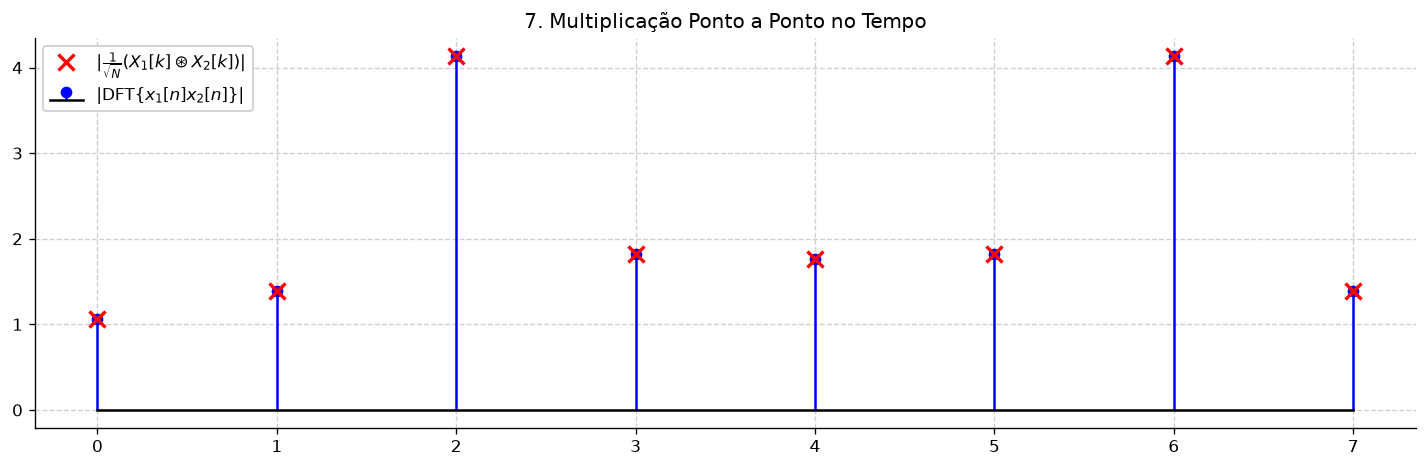

In [ ]:
def convolucao_circular(a, b):
    """Calcula a convolução circular entre dois vetores de tamanho N."""
    N = len(a)
    y = np.zeros(N, dtype=complex)
    for n in range(N):
        for l in range(N):
            y[n] += a[l] * b[(n - l) % N]
    return y

# Variáveis já calculadas anteriormente
# N, n, k, x1, x2, X1, X2

# =====================================================================
# 4. Reversão Temporal
# =====================================================================
x1_rev = np.array([x1[(-i) % N] for i in range(N)])
esq_rev = DFT(x1_rev)
dir_rev = np.array([X1[(-i) % N] for i in range(N)])

print("="*90)
print("PROPRIEDADE 4: REVERSÃO TEMPORAL")
print("Conclusão: Reverter um sinal no tempo de forma circular equivale a reverter o seu")
print("espectro na frequência também de forma circular. O gráfico abaixo compara as partes")
print("imaginárias de ambos os lados da equação. A sobreposição exata dos marcadores")
print("azuis e vermelhos comprova a propriedade.")
print("="*90)

fig4, ax4 = plt.subplots(figsize=(12, 4))
ax4.stem(k, np.imag(esq_rev), linefmt="b-", markerfmt="bo", basefmt="k-", label="Im{DFT{$x_1[(-n)\\mathrm{ mod }N]$}}")
ax4.plot(k, np.imag(dir_rev), "rx", markersize=10, markeredgewidth=2, label="Im{$X_1[(-k)\\mathrm{ mod }N]$}")
ax4.set_title("4. Reversão Temporal (Comparação da Parte Imaginária)")
ax4.legend()
ax4.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# =====================================================================
# 5. Conjugação Complexa
# =====================================================================
x_c = x1 + 1j * x2
X_c = DFT(x_c)
esq_conj = DFT(np.conj(x_c))
dir_conj = np.array([np.conj(X_c[(-i) % N]) for i in range(N)])

print("\n" + "="*90)
print("PROPRIEDADE 5: CONJUGAÇÃO COMPLEXA")
print("Conclusão: Aplicar a conjugação complexa em um sinal no domínio do tempo resulta em")
print("um espectro que é conjugado e também revertido circularmente. O gráfico abaixo compara o")
print("módulo (magnitude) de ambos os lados. A coincidência total demonstra a validade da propriedade.")
print("="*90)

fig5, ax5 = plt.subplots(figsize=(12, 4))
ax5.stem(k, np.abs(esq_conj), linefmt="b-", markerfmt="bo", basefmt="k-", label="|DFT{$x^*[n]$}|")
ax5.plot(k, np.abs(dir_conj), "rx", markersize=10, markeredgewidth=2, label="$|X^*[(-k)\\mathrm{ mod }N]|$")
ax5.set_title("5. Conjugação Complexa (Comparação do Módulo)")
ax5.legend()
ax5.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# =====================================================================
# 6. Convolução Circular no Tempo
# =====================================================================
esq_conv = DFT(convolucao_circular(x1, x2))
dir_conv = np.sqrt(N) * X1 * X2

print("\n" + "="*90)
print("PROPRIEDADE 6: CONVOLUÇÃO CIRCULAR NO TEMPO")
print("Conclusão: Esta é uma das propriedades MAIS IMPORTANTES do processamento de sinais!")
print("Fazer uma convolução circular no domínio do tempo é matematicamente equivalente a apenas")
print("multiplicar os sinais ponto a ponto no domínio da frequência (escalados por √N na nossa convenção).")
print("A sobreposição perfeita dos módulos prova esse poderoso teorema da convolução.")
print("="*90)

fig6, ax6 = plt.subplots(figsize=(12, 4))
ax6.stem(k, np.abs(esq_conv), linefmt="b-", markerfmt="bo", basefmt="k-", label="|DFT{$x_1[n] \\circledast x_2[n]$}|")
ax6.plot(k, np.abs(dir_conv), "rx", markersize=10, markeredgewidth=2, label="$|\\sqrt{N} X_1[k] X_2[k]|$")
ax6.set_title("6. Convolução Circular no Tempo")
ax6.legend()
ax6.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# =====================================================================
# 7. Multiplicação Ponto a Ponto no Tempo
# =====================================================================
esq_mult = DFT(x1 * x2)
dir_mult = (1 / np.sqrt(N)) * convolucao_circular(X1, X2)

print("\n" + "="*90)
print("PROPRIEDADE 7: MULTIPLICAÇÃO PONTO A Ponto NO TEMPO")
print("Conclusão: Pelo princípio da dualidade, o inverso da propriedade anterior também é")
print("verdadeiro: multiplicar dois sinais no tempo equivale a realizar uma convolução circular")
print("de seus espectros na frequência (com um fator de escala de 1/√N). A equivalência dos")
print("pontos no gráfico atesta a dualidade.")
print("="*90)

fig7, ax7 = plt.subplots(figsize=(12, 4))
ax7.stem(k, np.abs(esq_mult), linefmt="b-", markerfmt="bo", basefmt="k-", label="|DFT{$x_1[n] x_2[n]$}|")
ax7.plot(k, np.abs(dir_mult), "rx", markersize=10, markeredgewidth=2, label="$|\\frac{1}{\\sqrt{N}}(X_1[k] \\circledast X_2[k])|$")
ax7.set_title("7. Multiplicação Ponto a Ponto no Tempo")
ax7.legend()
ax7.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### Teorema de Parseval, Periodicidade e Simetria para Sinais Reais

8. **Teorema de Parseval:** $\sum_{n=0}^{N-1} x[n] y^*[n] = \sum_{k=0}^{N-1} X[k] Y^*[k]$. Quando $x[n] = y[n]$, demonstra que a soma da energia amostra a amostra no tempo ($\sum |x[n]|^2$) é idêntica à energia total acumulada nos coeficientes espectrais ($\sum |X[k]|^2$).
9. **Periodicidade:** $X[k + N] = X[k]$. Avaliando a equação da DFT para índices fora de $[0, N-1]$, o espectro se repete periodicamente a cada $N$ amostras .
10. **Simetria para sinais reais ($x[n] \in \mathbb{R}$):** $X[N - k] = X^*[k]$. Isso implica que o módulo $|X[k]|$ e a parte real possuem **simetria par** em relação a $N/2$, enquanto a fase e a parte imaginária possuem **simetria ímpar** ($\text{Im}\{X[k]\} = -\text{Im}\{X[N-k]\}$).

PROPRIEDADE 8: TEOREMA DE PARSEVAL
Conclusão: O Teorema de Parseval dita a conservação de energia. Como a DFT é
definida como uma 'transformada unitária' no nosso caso, a energia total do
sinal calculada no domínio do tempo é idêntica à energia no domínio da frequência.
O gráfico de barras abaixo mostra que as alturas das colunas azul (tempo) e
vermelha (frequência) são exatamente iguais, confirmando a conservação de energia e o produto interno.


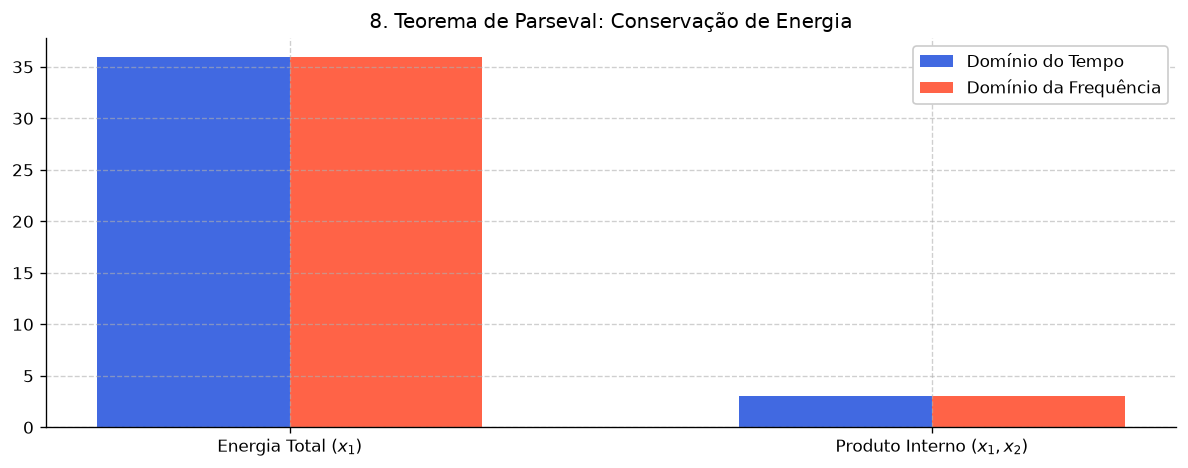


PROPRIEDADE 9: PERIODICIDADE
Conclusão: A DFT pressupõe matematicamente que o sinal no tempo é periódico com período N.
Portanto, o espectro gerado na frequência também se repete infinitamente a cada N amostras.
No gráfico, vemos que o 2º período (em vermelho pontilhado, para k de N até 2N-1)
é uma cópia idêntica do 1º período (em azul, para k de 0 até N-1).


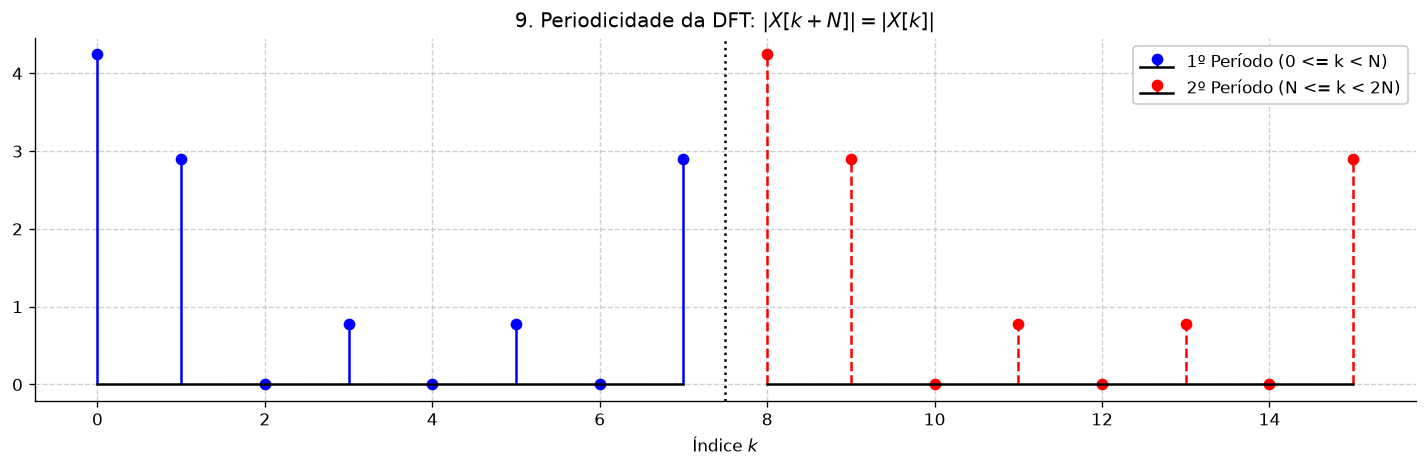


PROPRIEDADE 10: SIMETRIA PARA SINAIS REAIS
Conclusão: Para um sinal puramente real no tempo, seu espectro apresenta propriedades
de simetria conjugada em relação à frequência de Nyquist (o eixo verde N/2).
Gráfico Esquerdo: A parte real tem simetria PAR. Ela é um reflexo exato como um espelho.
Gráfico Direito: A parte imaginária tem simetria ÍMPAR. Ela é refletida e com o sinal invertido.
A sobreposição perfeita dos marcadores comprova essa propriedade estrutural da DFT.


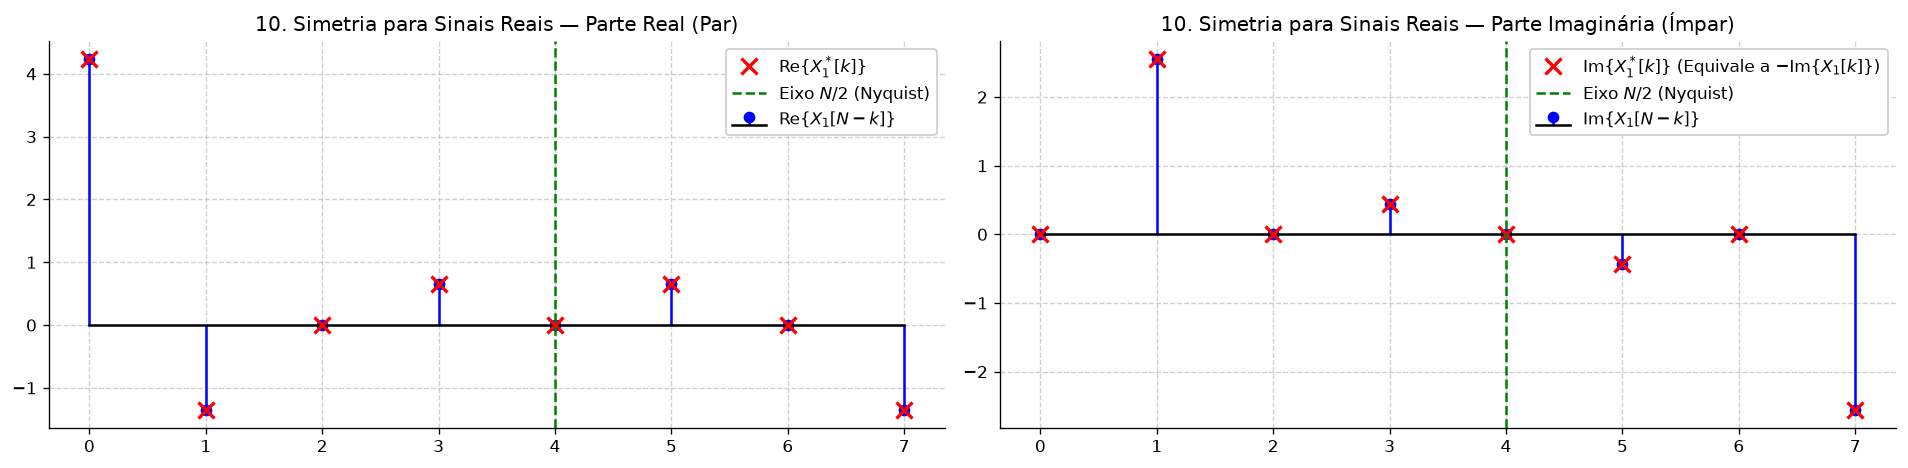

In [ ]:
# Variáveis já calculadas anteriormente 
# N, n, k, x1, x2, X1, X2

# =====================================================================
# 8. Teorema de Parseval
# =====================================================================
energia_tempo = np.sum(np.abs(x1) ** 2)
energia_freq = np.sum(np.abs(X1) ** 2)
prod_int_tempo = np.real(np.sum(x1 * np.conj(x2)))
prod_int_freq = np.real(np.sum(X1 * np.conj(X2)))

print("="*90)
print("PROPRIEDADE 8: TEOREMA DE PARSEVAL")
print("Conclusão: O Teorema de Parseval dita a conservação de energia. Como a DFT é")
print("definida como uma 'transformada unitária' no nosso caso, a energia total do")
print("sinal calculada no domínio do tempo é idêntica à energia no domínio da frequência.")
print("O gráfico de barras abaixo mostra que as alturas das colunas azul (tempo) e")
print("vermelha (frequência) são exatamente iguais, confirmando a conservação de energia e o produto interno.")
print("="*90)

fig8, ax8 = plt.subplots(figsize=(10, 4))
categorias = ["Energia Total ($x_1$)", "Produto Interno ($x_1, x_2$)"]
val_tempo = [energia_tempo, prod_int_tempo]
val_freq = [energia_freq, prod_int_freq]
pos = np.arange(len(categorias))

ax8.bar(pos - 0.15, val_tempo, width=0.3, label="Domínio do Tempo", color="royalblue")
ax8.bar(pos + 0.15, val_freq, width=0.3, label="Domínio da Frequência", color="tomato")
ax8.set_xticks(pos)
ax8.set_xticklabels(categorias)
ax8.set_title("8. Teorema de Parseval: Conservação de Energia")
ax8.legend()
ax8.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# =====================================================================
# 9. Periodicidade
# =====================================================================
# Avaliando a equação da DFT para k estendendo de 0 até 2N - 1
k_estendido = np.arange(2 * N)
X1_estendido = np.array([
    np.sum(x1 * np.exp(-1j * (2 * np.pi / N) * ki * n)) / np.sqrt(N)
    for ki in k_estendido
])

print("\n" + "="*90)
print("PROPRIEDADE 9: PERIODICIDADE")
print("Conclusão: A DFT pressupõe matematicamente que o sinal no tempo é periódico com período N.")
print("Portanto, o espectro gerado na frequência também se repete infinitamente a cada N amostras.")
print("No gráfico, vemos que o 2º período (em vermelho pontilhado, para k de N até 2N-1)")
print("é uma cópia idêntica do 1º período (em azul, para k de 0 até N-1).")
print("="*90)

fig9, ax9 = plt.subplots(figsize=(12, 4))
ax9.stem(k_estendido[:N], np.abs(X1_estendido[:N]), linefmt="b-", markerfmt="bo", basefmt="k-", label="1º Período (0 <= k < N)")
ax9.stem(k_estendido[N:], np.abs(X1_estendido[N:]), linefmt="r--", markerfmt="ro", basefmt="k-", label="2º Período (N <= k < 2N)")
ax9.axvline(N - 0.5, color="black", linestyle=":")
ax9.set_title("9. Periodicidade da DFT: $|X[k+N]| = |X[k]|$")
ax9.set_xlabel("Índice $k$")
ax9.legend()
ax9.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# =====================================================================
# 10. Simetria para sinais reais
# =====================================================================
X1_N_menos_k = np.array([X1[(N - i) % N] for i in range(N)])
X1_conjugado = np.conj(X1)

print("\n" + "="*90)
print("PROPRIEDADE 10: SIMETRIA PARA SINAIS REAIS")
print("Conclusão: Para um sinal puramente real no tempo, seu espectro apresenta propriedades")
print("de simetria conjugada em relação à frequência de Nyquist (o eixo verde N/2).")
print("Gráfico Esquerdo: A parte real tem simetria PAR. Ela é um reflexo exato como um espelho.")
print("Gráfico Direito: A parte imaginária tem simetria ÍMPAR. Ela é refletida e com o sinal invertido.")
print("A sobreposição perfeita dos marcadores comprova essa propriedade estrutural da DFT.")
print("="*90)

fig10, axs10 = plt.subplots(1, 2, figsize=(16, 4))

# Parte Real (Simetria Par) - Usando raw strings (r"") para evitar erros de escape com os símbolos
axs10[0].stem(k, np.real(X1_N_menos_k), linefmt="b-", markerfmt="bo", basefmt="k-", label=r"$\mathrm{Re}\{X_1[N-k]\}$")
axs10[0].plot(k, np.real(X1_conjugado), "rx", markersize=10, markeredgewidth=2, label=r"$\mathrm{Re}\{X_1^*[k]\}$")
axs10[0].axvline(N / 2, color="green", linestyle="--", label="Eixo $N/2$ (Nyquist)")
axs10[0].set_title("10. Simetria para Sinais Reais — Parte Real (Par)")
axs10[0].legend()
axs10[0].grid(True, linestyle="--", alpha=0.6)

# Parte Imaginária (Simetria Ímpar)
axs10[1].stem(k, np.imag(X1_N_menos_k), linefmt="b-", markerfmt="bo", basefmt="k-", label=r"$\mathrm{Im}\{X_1[N-k]\}$")
axs10[1].plot(k, np.imag(X1_conjugado), "rx", markersize=10, markeredgewidth=2, label=r"$\mathrm{Im}\{X_1^*[k]\}$ (Equivale a $-\mathrm{Im}\{X_1[k]\}$)")
axs10[1].axvline(N / 2, color="green", linestyle="--", label="Eixo $N/2$ (Nyquist)")
axs10[1].set_title("10. Simetria para Sinais Reais — Parte Imaginária (Ímpar)")
axs10[1].legend()
axs10[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

### Amostragem no Tempo e Amostragem na Frequência (Zero-Padding)

11. **Amostragem no tempo (Expansão por zeros):** 
Inserir $M-1$ zeros entre as amostras de $x[n]$ gera um sinal expandido de comprimento $M \cdot N$ cujo espectro na frequência é o espectro original $X[k]$ **repetido $M$ vezes** no domínio da frequência.

12. **Amostragem na frequência (Zero-padding no tempo):** 
Preencher um sinal $x[n]$ de comprimento $L$ com zeros ao final até atingir um tamanho $N > L$ (**zero-padding**) resulta em uma **DFT interpolada com $N$ pontos**, tornando o espectro discreto cada vez mais denso e próximo da Transformada de Fourier de Tempo Discreto (DTFT) contínua.

PROPRIEDADE 11: AMOSTRAGEM NO TEMPO (EXPANSÃO POR ZEROS)
Conclusão: Ao inserir M-1 zeros entre as amostras do sinal no domínio do tempo, o eixo
de frequência sofre uma compressão, fazendo com que o espectro original X[k] apareça
repetido M vezes no domínio da frequência. O gráfico da direita mostra claramente
a forma de onda da esquerda repetida 3 vezes.


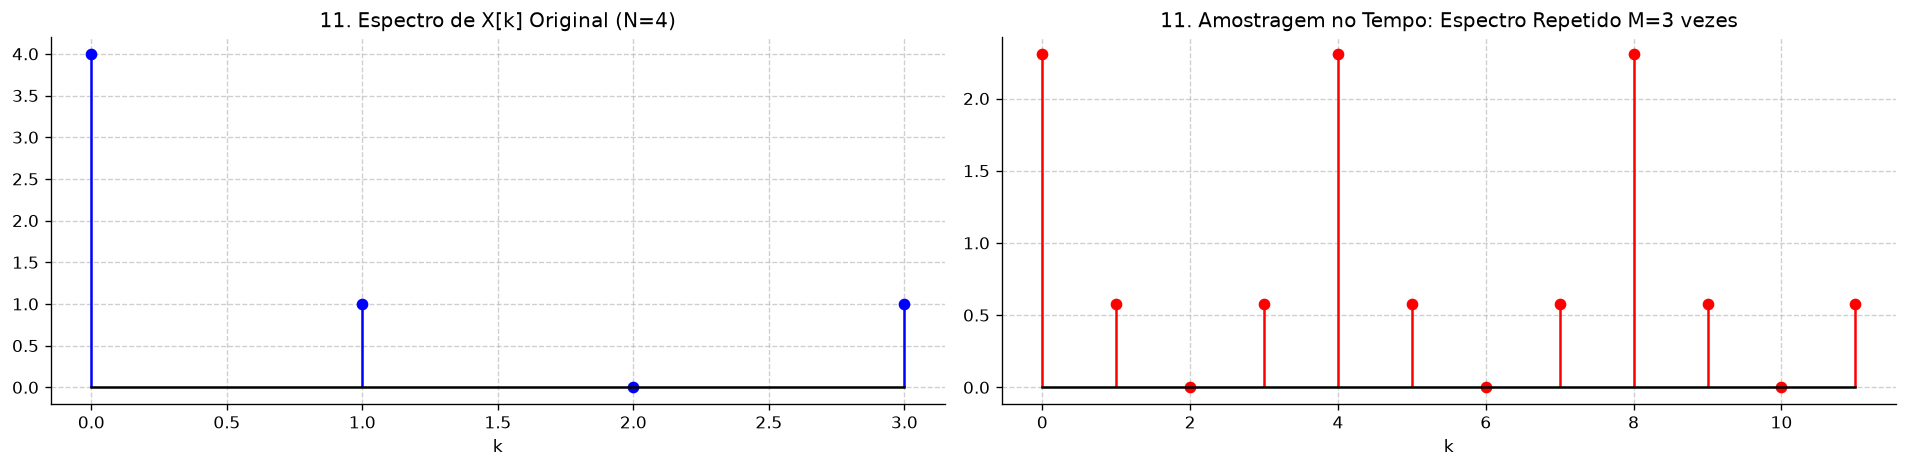


PROPRIEDADE 12: AMOSTRAGEM NA FREQUÊNCIA (ZERO-PADDING)
Conclusão: Quanto maior é o número de zeros acrescentados ao sinal no tempo (zero-padding),
mais a DFT se parece com a sua transformada de Fourier de tempo contínuo (DTFT)].
Isso ocorre devido ao maior número de amostras tomadas no intervalo].
Com N=8 (esquerda), a DFT não tem resolução suficiente para identificar os dois picos].
Elevando N para 32 (direita), a inserção de zeros funciona como uma interpolação na frequência,
revelando a silhueta da DTFT e os picos perfeitamente delineados].


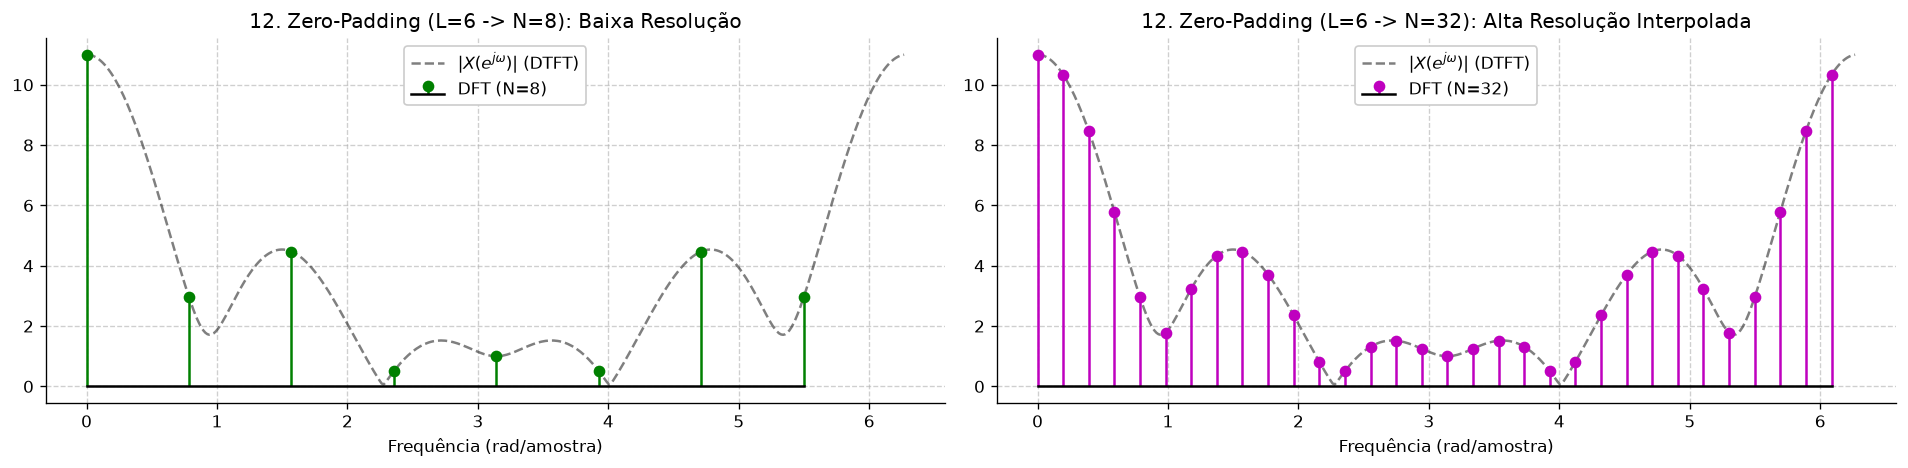

In [63]:
# =====================================================================
# 11. Amostragem no tempo (Repetição espectral)
# =====================================================================
M = 3
x_curto = np.array([1.0, 2.0, 3.0, 2.0])
X_curto = DFT(x_curto)

# Inserindo M-1 zeros entre as amostras
x_expandido = np.zeros(len(x_curto) * M)
x_expandido[::M] = x_curto
X_expandido = DFT(x_expandido)

print("="*90)
print("PROPRIEDADE 11: AMOSTRAGEM NO TEMPO (EXPANSÃO POR ZEROS)")
print("Conclusão: Ao inserir M-1 zeros entre as amostras do sinal no domínio do tempo, o eixo")
print("de frequência sofre uma compressão, fazendo com que o espectro original X[k] apareça")
print("repetido M vezes no domínio da frequência. O gráfico da direita mostra claramente")
print("a forma de onda da esquerda repetida 3 vezes.")
print("="*90)

fig11, axs11 = plt.subplots(1, 2, figsize=(16, 4))

axs11[0].stem(np.abs(X_curto), linefmt="b-", markerfmt="bo", basefmt="k-")
axs11[0].set_title("11. Espectro de X[k] Original (N=4)")
axs11[0].set_xlabel("k")
axs11[0].grid(True, linestyle="--", alpha=0.6)

axs11[1].stem(np.abs(X_expandido), linefmt="r-", markerfmt="ro", basefmt="k-")
axs11[1].set_title(f"11. Amostragem no Tempo: Espectro Repetido M={M} vezes")
axs11[1].set_xlabel("k")
axs11[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# =====================================================================
# 12. Amostragem na frequência (Zero-padding)
# =====================================================================
x_base = np.array([2.0, 3.0, 1.5, 1.0, 1.5, 2.0])  # L = 6 amostras
x_zp8 = np.pad(x_base, (0, 8 - len(x_base)), "constant")  # N = 8
x_zp32 = np.pad(x_base, (0, 32 - len(x_base)), "constant")  # N = 32

# DTFT Contínua para referência visual do "contorno" 
w_cont = np.linspace(0, 2 * np.pi, 400, endpoint=False)
DTFT_cont = np.array([np.sum(x_base * np.exp(-1j * w * np.arange(len(x_base)))) for w in w_cont])

X_zp8 = DFT(x_zp8)
X_zp32 = DFT(x_zp32)

print("\n" + "="*90)
print("PROPRIEDADE 12: AMOSTRAGEM NA FREQUÊNCIA (ZERO-PADDING)")
print("Conclusão: Quanto maior é o número de zeros acrescentados ao sinal no tempo (zero-padding),")
print("mais a DFT se parece com a sua transformada de Fourier de tempo contínuo (DTFT)].")
print("Isso ocorre devido ao maior número de amostras tomadas no intervalo].")
print("Com N=8 (esquerda), a DFT não tem resolução suficiente para identificar os dois picos].")
print("Elevando N para 32 (direita), a inserção de zeros funciona como uma interpolação na frequência,")
print("revelando a silhueta da DTFT e os picos perfeitamente delineados].")
print("="*90)

fig12, axs12 = plt.subplots(1, 2, figsize=(16, 4))

axs12[0].plot(w_cont, np.abs(DTFT_cont), "k--", alpha=0.5, label="$|X(e^{j\\omega})|$ (DTFT)")
axs12[0].stem(np.arange(8) * 2 * np.pi / 8, np.abs(X_zp8) * np.sqrt(8), linefmt="g-", markerfmt="go", basefmt="k-", label="DFT (N=8)")
axs12[0].set_title("12. Zero-Padding (L=6 -> N=8): Baixa Resolução")
axs12[0].set_xlabel("Frequência (rad/amostra)")
axs12[0].legend()
axs12[0].grid(True, linestyle="--", alpha=0.6)

axs12[1].plot(w_cont, np.abs(DTFT_cont), "k--", alpha=0.5, label="$|X(e^{j\\omega})|$ (DTFT)")
axs12[1].stem(np.arange(32) * 2 * np.pi / 32, np.abs(X_zp32) * np.sqrt(32), linefmt="m-", markerfmt="mo", basefmt="k-", label="DFT (N=32)")
axs12[1].set_title("12. Zero-Padding (L=6 -> N=32): Alta Resolução Interpolada")
axs12[1].set_xlabel("Frequência (rad/amostra)")
axs12[1].legend()
axs12[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 2. Convolução Linear a partir da Convolução Circular utilizando DFT/IDFT

O produto de duas DFTs de comprimento $N$ resulta na **convolução circular** no domínio do tempo. Quando usamos um tamanho $N < L + K - 1$ (onde $L$ é a duração de $x[n]$ e $K$ é a duração de $h[n]$), as repetições periódicas se sobrepõem no tempo (*aliasing temporal*), distorcendo as amostras iniciais do resultado.

Para obter a **convolução linear exata** a partir da convolução circular usando DFT/IDFT, preenchemos ambos os sinais com zeros (*zero-padding*) até um tamanho mínimo de:
$$N \ge L + K - 1$$

Em seguida, aplicamos a relação da tabela:
$$y[n] = \text{IDFT}\left\{ \sqrt{N} \cdot \text{DFT}\{x_{zp}[n]\} \cdot \text{DFT}\{h_{zp}[n]\} \right\}$$

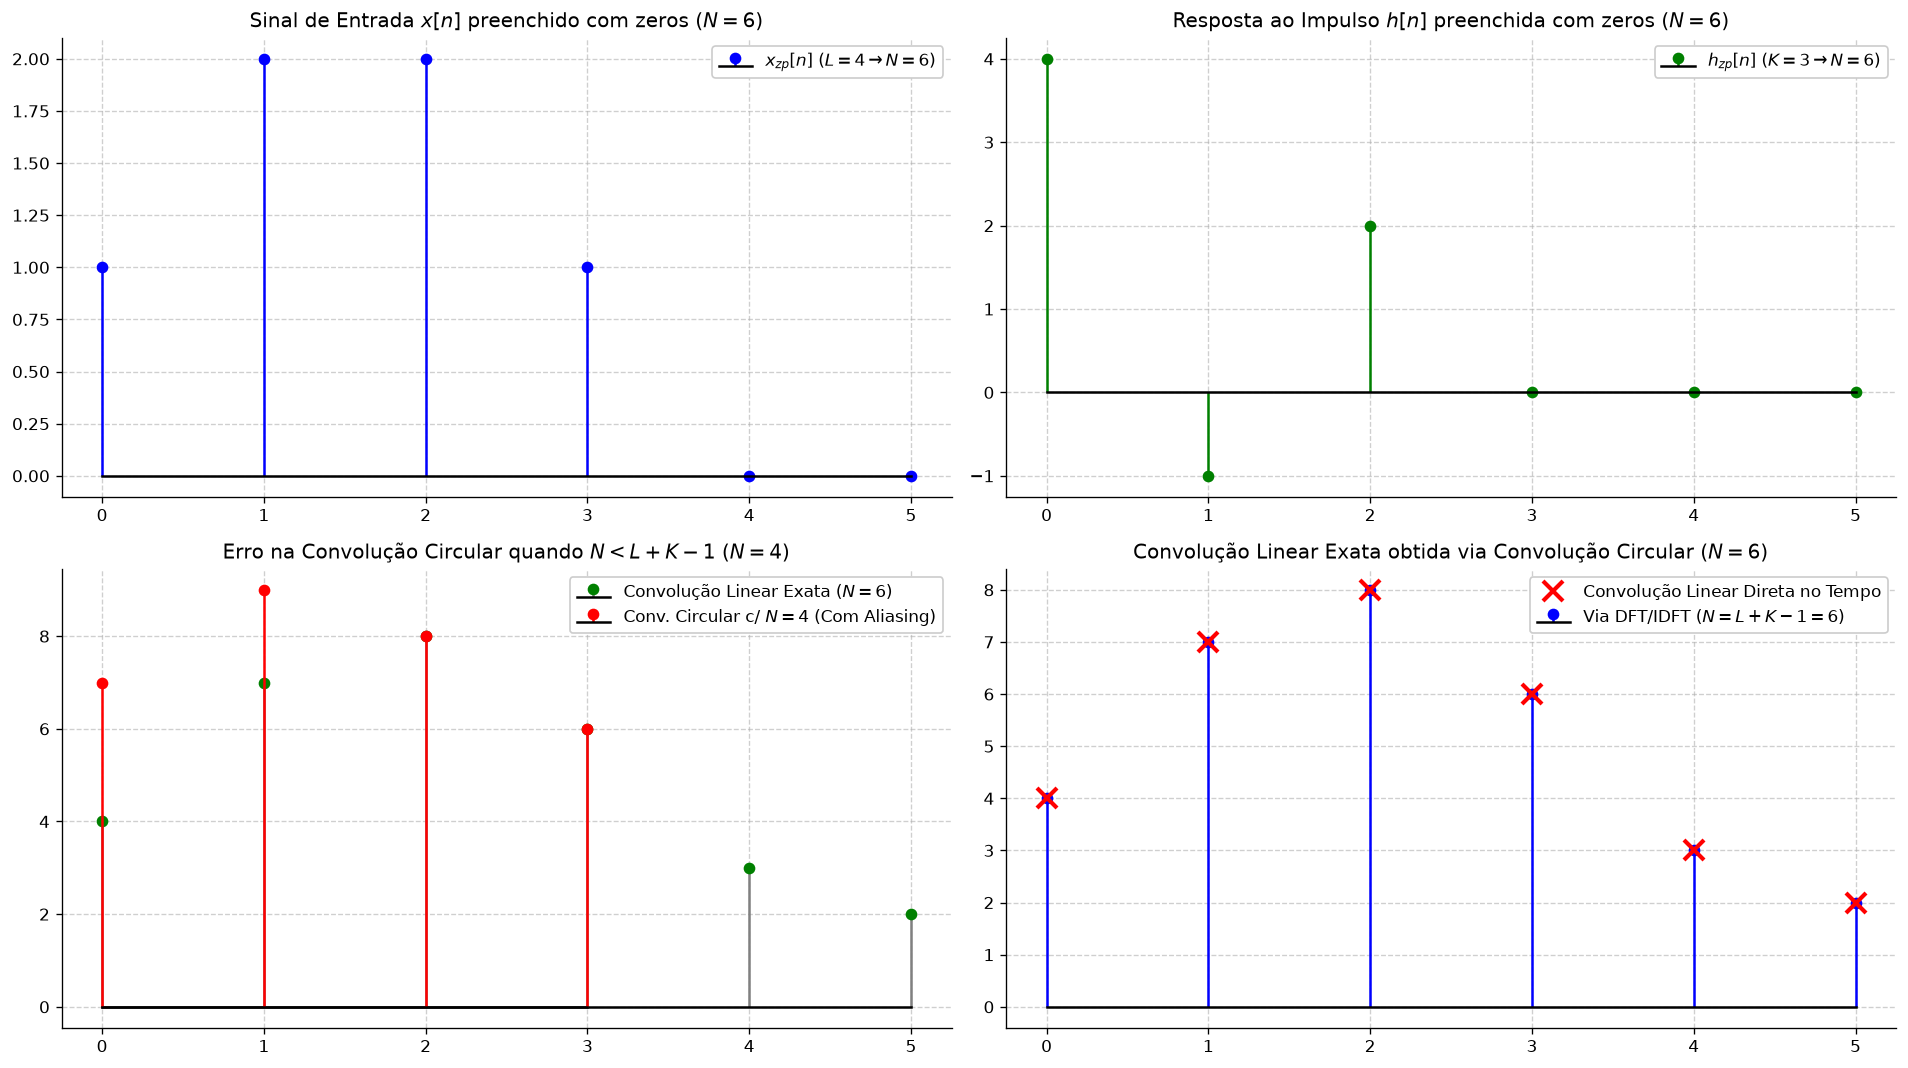

In [ ]:
def convolucao_linear_direta(x, h):
  """Calcula a convolução linear diretamente no domínio do tempo."""
  L, K = len(x), len(h)
  N_lin = L + K - 1
  y = np.zeros(N_lin)
  for n in range(N_lin):
    for l in range(L):
      if 0 <= (n - l) < K:
        y[n] += x[l] * h[n - l]
  return y


def convolucao_linear_via_dft(x, h):
  """Obtém a convolução linear a partir da convolução circular com zero-padding (N = L + K - 1)."""
  L, K = len(x), len(h)
  N = L + K - 1

  # Zero-padding para comprimento N
  x_zp = np.zeros(N)
  h_zp = np.zeros(N)
  x_zp[:L] = x
  h_zp[:K] = h

  # Cálculo via DFT e IDFT
  X_zp = DFT(x_zp)
  H_zp = DFT(h_zp)
  y = np.real(IDFT(np.sqrt(N) * X_zp * H_zp))
  return y, x_zp, h_zp


# Sinais de entrada: x[n] com L = 4 amostras e h[n] com K = 3 amostras
x_in = np.array([1.0, 2.0, 2.0, 1.0])
h_in = np.array([4.0, -1.0, 2.0])

# 1. Convolução Linear Direta e via DFT com Zero-Padding (N = 4 + 3 - 1 = 6)
y_direta = convolucao_linear_direta(x_in, h_in)
y_dft_correta, x_pad, h_pad = convolucao_linear_via_dft(x_in, h_in)

# 2. Convolução Circular SEM Zero-Padding suficiente (N = 4 < 6), gerando interferência temporal
N_curto = 4
h_curto = np.pad(h_in, (0, N_curto - len(h_in)), "constant")
y_circ_alias = np.real(IDFT(np.sqrt(N_curto) * DFT(x_in) * DFT(h_curto)))

# PLOTAGEM
fig, axs = plt.subplots(2, 2, figsize=(16, 9))

# Sinais com Zero-Padding (N = 6)
axs[0, 0].stem(
    np.arange(len(x_pad)),
    x_pad,
    linefmt="b-",
    markerfmt="bo",
    basefmt="k-",
    label="$x_{zp}[n]$ ($L=4 \\rightarrow N=6$)",
)
axs[0, 0].set_title("Sinal de Entrada $x[n]$ preenchido com zeros ($N=6$)")
axs[0, 0].legend()
axs[0, 0].grid(True, linestyle="--", alpha=0.6)

axs[0, 1].stem(
    np.arange(len(h_pad)),
    h_pad,
    linefmt="g-",
    markerfmt="go",
    basefmt="k-",
    label="$h_{zp}[n]$ ($K=3 \\rightarrow N=6$)",
)
axs[0, 1].set_title("Resposta ao Impulso $h[n]$ preenchida com zeros ($N=6$)")
axs[0, 1].legend()
axs[0, 1].grid(True, linestyle="--", alpha=0.6)

# Convolução Circular com N=4 (Mostrando o erro por falta de zero-padding)
axs[1, 0].stem(
    np.arange(len(y_direta)),
    y_direta,
    linefmt="gray",
    markerfmt="go",
    basefmt="k-",
    label="Convolução Linear Exata ($N=6$)",
)
axs[1, 0].stem(
    np.arange(len(y_circ_alias)),
    y_circ_alias,
    linefmt="r-",
    markerfmt="ro",
    basefmt="k-",
    label="Conv. Circular c/ $N=4$ (Com Aliasing)",
)
axs[1, 0].set_title(
    "Erro na Convolução Circular quando $N < L + K - 1$ ($N=4$)"
)
axs[1, 0].legend()
axs[1, 0].grid(True, linestyle="--", alpha=0.6)

# Sobreposição perfeita: Convolução Linear Direta vs Convolução Circular via DFT (N=6)
axs[1, 1].stem(
    np.arange(len(y_dft_correta)),
    y_dft_correta,
    linefmt="b-",
    markerfmt="bo",
    basefmt="k-",
    label="Via DFT/IDFT ($N = L+K-1 = 6$)",
)
axs[1, 1].plot(
    np.arange(len(y_direta)),
    y_direta,
    "rx",
    markersize=12,
    markeredgewidth=2.5,
    label="Convolução Linear Direta no Tempo",
)
axs[1, 1].set_title(
    "Convolução Linear Exata obtida via Convolução Circular ($N = 6$)"
)
axs[1, 1].legend()
axs[1, 1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

plt.show()

# Validação usando a biblioteca numpy


In [65]:
y_numpy = np.convolve(x_in, h_in, mode='full')

print("=" * 90)
print(f"{'Índice (n)':<12} | {'convolucao_linear_via_dft':<35} | {'Convolução NumPy'}")
print("-" * 90)
for i in range(len(y_dft_correta)):
    print(f"{i:<12} | {np.round(y_dft_correta[i], 4):<35} | {np.round(y_numpy[i], 4)}")
print("=" * 90)


Índice (n)   | convolucao_linear_via_dft           | Convolução NumPy
------------------------------------------------------------------------------------------
0            | 4.0                                 | 4.0
1            | 7.0                                 | 7.0
2            | 8.0                                 | 8.0
3            | 6.0                                 | 6.0
4            | 3.0                                 | 3.0
5            | 2.0                                 | 2.0


# 3. Filtragem de Sinais Longos: Overlap-and-Add e Overlap-and-Save

Quando precisamos aplicar a convolução linear entre uma resposta ao impulso curta $h[n]$ (de tamanho $K$) e um sinal de entrada $x[n]$ muito longo, particionamos $x[n]$ em blocos menores de tamanho $N$. Existem dois métodos clássicos para reconstruir o sinal final a partir da convolução desses blocos, compensando as distorções da convolução circular:

* **Sobreposição e Soma (Overlap-and-Add):** O sinal é dividido em blocos não sobrepostos de tamanho $N$. O filtro e o bloco são preenchidos com zeros até o tamanho $N + K - 1$. Após a convolução circular, as $K-1$ últimas amostras de um bloco se sobrepõem às $K-1$ primeiras amostras do bloco seguinte, e devem ser **somadas** para formar a saída correta.
* **Sobreposição e Armazenamento (Overlap-and-Save):** O sinal é dividido em blocos de tamanho $N$, mas cada bloco avança copiando as $K-1$ amostras do bloco anterior (sobreposição na entrada). A convolução circular é feita com tamanho fixo $N$. Como não fizemos o zero-padding completo, as $K-1$ primeiras amostras de cada bloco resultante sofrem *aliasing* e são sumariamente **descartadas**. As amostras restantes são armazenadas sequencialmente.

MÉTODOS DE FILTRAGEM EM BLOCOS: OVERLAP-AND-ADD E OVERLAP-AND-SAVE
Conclusão: Em vez de processar sinais longos de uma vez, a divisão em blocos economiza memória e processamento.
-> O método Overlap-and-Add evita o aliasing adicionando zeros, e as partes sobrepostas são SOMADAS na saída.
-> O método Overlap-and-Save sobrepõe o sinal na entrada e DESCARTA as amostras corrompidas por aliasing.
A correspondência perfeita (marcador em 'x' vermelho sobre a linha base) comprova matematicamente as duas técnicas.


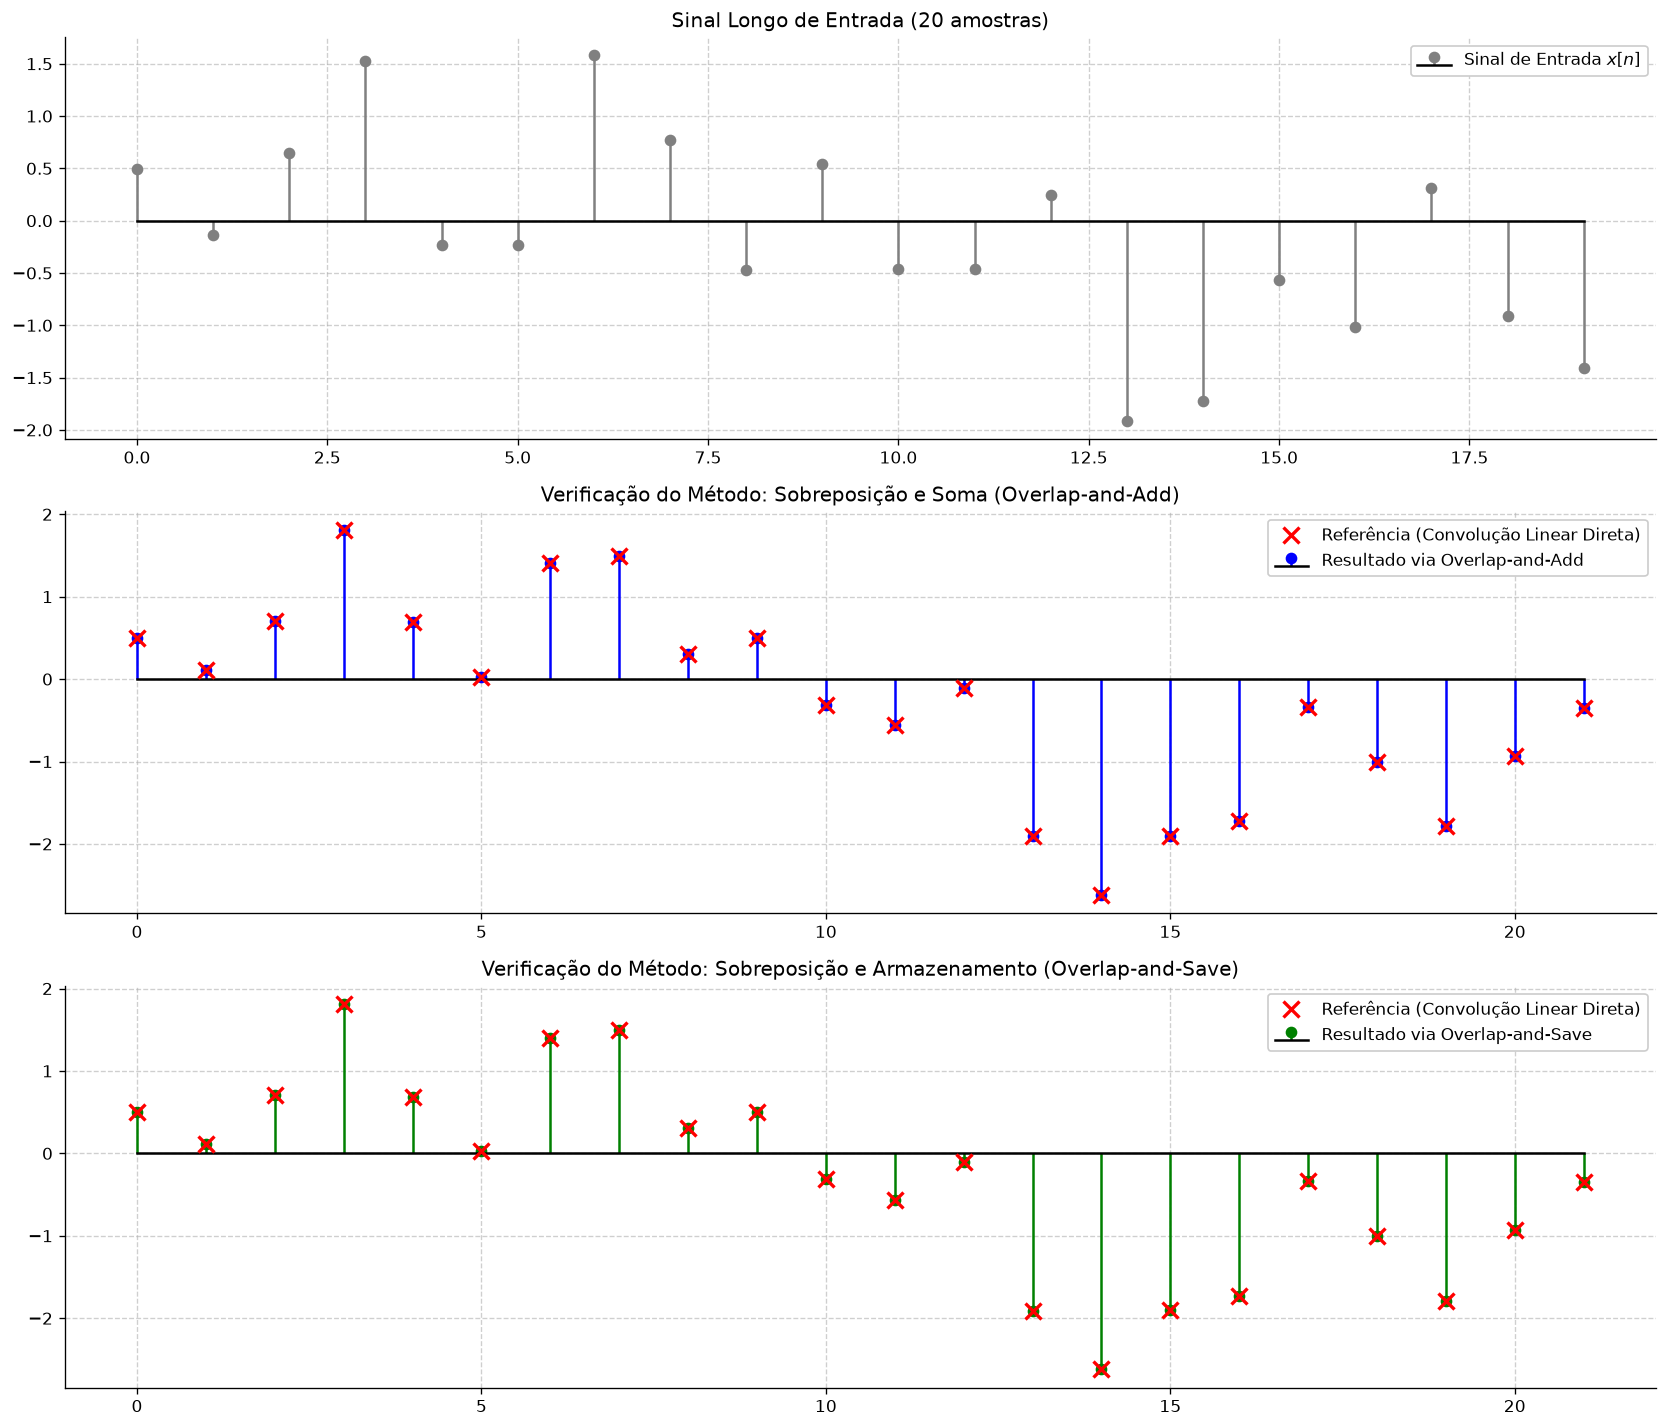

In [ ]:

def overlap_and_add(x, h, N_bloco):
    """Implementa o método Overlap-and-Add (Sobreposição e Soma)."""
    K = len(h)
    N_dft = N_bloco + K - 1 # Tamanho livre de aliasing temporal
    
    # Preenche h com zeros até N_dft
    h_pad = np.pad(h, (0, N_dft - K), 'constant')
    H = DFT(h_pad) # USANDO A FUNÇÃO IMPLENTADA
    
    y = np.zeros(len(x) + K - 1)
    
    for m in range(0, len(x), N_bloco):
        x_bloco = x[m : m + N_bloco]
        # Preenche o bloco atual com zeros até N_dft
        x_pad = np.pad(x_bloco, (0, N_dft - len(x_bloco)), 'constant')
        
        # Convolução Circular via DFT
        X_bloco = DFT(x_pad)
        y_bloco = np.real(IDFT(np.sqrt(N_dft) * X_bloco * H))
        
        # SOMA a sobreposição na posição correta
        y[m : m + N_dft] += y_bloco[:len(y[m : m + N_dft])]
        
    return y

def overlap_and_save(x, h, N_bloco):
    """Implementa o método Overlap-and-Save."""
    K = len(h)
    # Garante que o bloco é maior que o filtro
    if N_bloco < K: 
        raise ValueError("O tamanho do bloco deve ser maior que o do filtro.")
        
    h_pad = np.pad(h, (0, N_bloco - K), 'constant')
    H = DFT(h_pad)
    
    y = []
    # Adiciona K-1 zeros no início para o primeiro bloco não perder dados
    x_ext = np.pad(x, (K - 1, 0), 'constant')
    
    passo = N_bloco - K + 1
    for m in range(0, len(x_ext) - K + 1, passo):
        x_bloco = x_ext[m : m + N_bloco]
        # Se for o último bloco e ficar menor que N_bloco, preenche com zeros
        if len(x_bloco) < N_bloco:
            x_bloco = np.pad(x_bloco, (0, N_bloco - len(x_bloco)), 'constant')
            
        X_bloco = DFT(x_bloco)
        y_bloco = np.real(IDFT(np.sqrt(N_bloco) * X_bloco * H))
        
        # DESCARTA as K-1 primeiras amostras (corrompidas por aliasing)
        y.extend(y_bloco[K - 1:])
        
    # Corta o excesso criado no final
    return np.array(y)[:len(x) + K - 1]


#TESTE
np.random.seed(42) # Semente fixa para o gráfico não ficar mudando
sinal_longo = np.random.randn(20)
filtro = np.array([1, 0.5, 0.25])

y_ola = overlap_and_add(sinal_longo, filtro, N_bloco=8)
y_ols = overlap_and_save(sinal_longo, filtro, N_bloco=8)
y_ref = convolucao_linear_direta(sinal_longo, filtro)


print("="*90)
print("MÉTODOS DE FILTRAGEM EM BLOCOS: OVERLAP-AND-ADD E OVERLAP-AND-SAVE")
print("Conclusão: Em vez de processar sinais longos de uma vez, a divisão em blocos economiza memória e processamento.")
print("-> O método Overlap-and-Add evita o aliasing adicionando zeros, e as partes sobrepostas são SOMADAS na saída.")
print("-> O método Overlap-and-Save sobrepõe o sinal na entrada e DESCARTA as amostras corrompidas por aliasing.")
print("A correspondência perfeita (marcador em 'x' vermelho sobre a linha base) comprova matematicamente as duas técnicas.")
print("="*90)

fig, axs = plt.subplots(3, 1, figsize=(14, 12))

# Gráfico 1: Sinal Longo Original
axs[0].stem(np.arange(len(sinal_longo)), sinal_longo, linefmt="gray", markerfmt="o", basefmt="k-", label="Sinal de Entrada $x[n]$")
axs[0].set_title("Sinal Longo de Entrada (20 amostras)")
axs[0].legend()
axs[0].grid(True, linestyle="--", alpha=0.6)

# Gráfico 2: Verificação do Overlap-and-Add
axs[1].stem(np.arange(len(y_ola)), y_ola, linefmt="b-", markerfmt="bo", basefmt="k-", label="Resultado via Overlap-and-Add")
axs[1].plot(np.arange(len(y_ref)), y_ref, "rx", markersize=10, markeredgewidth=2, label="Referência (Convolução Linear Direta)")
axs[1].set_title("Verificação do Método: Sobreposição e Soma (Overlap-and-Add)")
axs[1].legend()
axs[1].grid(True, linestyle="--", alpha=0.6)

# Gráfico 3: Verificação do Overlap-and-Save
axs[2].stem(np.arange(len(y_ols)), y_ols, linefmt="g-", markerfmt="go", basefmt="k-", label="Resultado via Overlap-and-Save")
axs[2].plot(np.arange(len(y_ref)), y_ref, "rx", markersize=10, markeredgewidth=2, label="Referência (Convolução Linear Direta)")
axs[2].set_title("Verificação do Método: Sobreposição e Armazenamento (Overlap-and-Save)")
axs[2].legend()
axs[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# 4.  DFT vs FFT (DIT e DIF)

O cálculo direto da Transformada Discreta de Fourier (DFT) de comprimento $N$ exige a resolução da somatória fundamental para cada índice de frequência $k$:

$$X[k] = \sum_{n=0}^{N-1} x[n] W_N^{kn}, \quad \text{onde } W_N = e^{-j\frac{2\pi}{N}}$$

Para computar todos os $N$ coeficientes espectrais, são necessárias $N^2$ multiplicações complexas e $N(N-1)$ adições complexas, resultando em uma complexidade assintótica de $\mathcal{O}(N^2)$. Para sinais longos, esse custo torna o processamento em tempo real inviável.

Os algoritmos de **Transformada de Fourier Rápida (FFT)**, popularizados por Cooley e Tukey em 1965, contornam esse gargalo aplicando a estratégia de "dividir para conquistar". Quando $N$ é uma potência de 2 ($N = 2^l$), o problema original é quebrado recursivamente ao longo de $l = \log_2 N$ estágios até restarem apenas transformadas elementares de comprimento 2, reduzindo drasticamente o custo computacional para $\mathcal{O}(N \log_2 N)$.

---

### O que é a Célula Borboleta (Butterfly)?

A **Célula Borboleta** é a unidade básica de processamento aritmético que se repete ao longo de todos os estágios da FFT. Ela recebe esse nome porque o diagrama de fluxo de sinal que conecta suas duas entradas às suas duas saídas possui linhas cruzadas que lembram o formato das asas de uma borboleta.

O segredo da eficiência da borboleta está na exploração das propriedades de **simetria e periodicidade** dos fatores de rotação (*twiddle factors* $W_L^k$) no círculo trigonométrico complexo. Em uma sub-transformada de tamanho $L$, o fator associado à segunda metade do espectro satisfaz a identidade:

$$W_L^{k + L/2} = W_L^k \cdot W_L^{L/2} = W_L^k \cdot e^{-j\pi} = -W_L^k$$

Graças a essa inversão de sinal ($-1$), não precisamos calcular duas multiplicações complexas independentes para obter um par de pontos simétricos. Calculamos o produto complexo uma única vez e o reaproveitamos — somando para obter o primeiro ramo e subtraindo para obter o segundo. Isso corta pela metade o número de multiplicações complexas necessárias em cada estágio do algoritmo, resultando em um total de apenas $\frac{N}{2} \log_2 N$ multiplicações complexas.

---

### Diferença entre Decimação no Tempo (DIT) e Decimação na Frequência (DIF)

Embora ambos os algoritmos de raiz 2 (*Radix-2*) alcancem exatamente a mesma complexidade de $\mathcal{O}(N \log_2 N)$ e produzam o mesmo espectro final, eles são matematicamente transpostos um em relação ao outro e diferem na **ordem** em que particionam os dados e aplicam a célula borboleta:

#### 1. FFT por Decimação no Tempo (DIT — *Decimation-in-Time*)
* **Como divide o sinal:** O particionamento ocorre no domínio do **tempo** (na entrada). A sequência $x[n]$ é dividida em duas subsequências de tamanho $N/2$: uma contendo as amostras de **índice temporal par** ($x[2n]$) e outra com as de **índice temporal ímpar** ($x[2n+1]$):
  $$X[k] = \underbrace{\sum_{n=0}^{N/2-1} x[2n] W_{N/2}^{nk}}_{X_e[k]} + W_N^k \underbrace{\sum_{n=0}^{N/2-1} x[2n+1] W_{N/2}^{nk}}_{X_o[k]}$$
* **Operação da Borboleta (DIT):** O fator de rotação $W_L^k$ multiplica o ramo inferior **antes** da soma e da subtração:
  $$\begin{cases} X_i[k] = X_{ie}[k] + W_L^k X_{io}[k] \\ X_i[k + L/2] = X_{ie}[k] - W_L^k X_{io}[k] \end{cases}$$
* **Fluxo de Execução (Código Recursivo):** Primeiro separamos os elementos pares e ímpares (`x[0::2]` e `x[1::2]`), fazemos as chamadas recursivas e, no retorno da recursão, aplicamos a borboleta para concatenar a primeira metade com a segunda metade do espectro. Em implementações iterativas (*in-place*), exige reversão de bits (*bit-reversal*) na entrada e entrega a saída na ordem natural.

#### 2. FFT por Decimação na Frequência (DIF — *Decimation-in-Frequency*)
* **Como divide o sinal:** O particionamento do vetor de entrada é feito dividindo o sinal temporal ao meio em blocos contíguos: a **primeira metade** ($x[n]$) e a **segunda metade** ($x[n + N/2]$), para $0 \le n < N/2$. A separação entre índices pares e ímpares ocorre no domínio da **frequência** (na saída, $X[2k]$ e $X[2k+1]$).
* **Operação da Borboleta (DIF):** Primeiro realizamos a soma e a subtração direta entre a primeira e a segunda metade do sinal. A multiplicação pelo fator de rotação $W_L^n$ acontece **depois** da subtração no ramo inferior:
  $$\begin{cases} S_{ie}[n] = S_i[n] + S_i[n + L/2] \\ S_{io}[n] = \left( S_i[n] - S_i[n + L/2] \right) W_L^n \end{cases}$$
* **Fluxo de Execução (Código Recursivo):** A célula borboleta é processada **antes** das chamadas recursivas. O ramo da soma alimenta a recursão que calculará as frequências pares (`X[0::2]`), enquanto o ramo da diferença ponderada alimenta a recursão das frequências ímpares (`X[1::2]`). Em implementações iterativas (*in-place*), recebe a entrada na ordem normal e entrega a saída em ordem de bits reversos.

VALIDAÇÃO
Índice (k)   | DFT (CPU)               | FFT DIF (CPU)           | DFT (GPU)               | FFT DIF (GPU)
----------------------------------------------------------------------------------------------------------------------
0            | (4.2426+0j)             | (4.2426+0j)             | (4.2426+0j)             | (4.2426+0j)
1            | (-1.3536-2.5607j)       | (-1.3536-2.5607j)       | (-1.3536-2.5607j)       | (-1.3536-2.5607j)
2            | 0j                      | 0j                      | 0j                      | 0j
3            | (0.6464-0.4393j)        | (0.6464-0.4393j)        | (0.6464-0.4393j)        | (0.6464-0.4393j)
4            | 0j                      | 0j                      | 0j                      | 0j
5            | (0.6464+0.4393j)        | (0.6464+0.4393j)        | (0.6464+0.4393j)        | (0.6464+0.4393j)
6            | (-0+0j)                 | 0j                      | (-0+0j)                 | 0j
7            | (-1.3536+2.5607j)       |

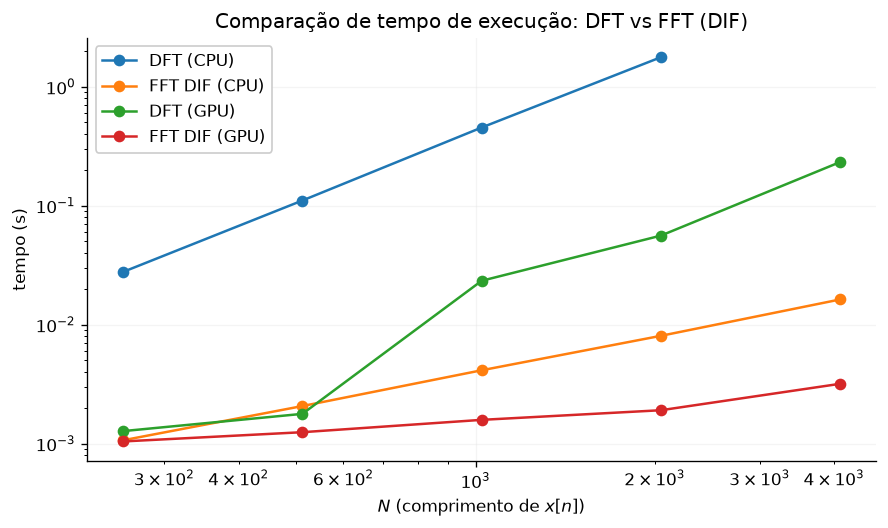

In [ ]:
import cupy as cp

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "legend.framealpha": 1.0,
})

#CPU

def FFT_DIF_radix2_cpu(x):
    """Núcleo recursivo da FFT Radix-2 por Decimação na Frequência (DIF) na CPU."""
    N = len(x)
    if N <= 1:
        return x
    if N % 2 > 0:
        raise ValueError("O tamanho de x deve ser uma potência de 2.")
        
    metade = N // 2
    x_sup = x[:metade]
    x_inf = x[metade:]
    
    # Célula Borboleta DIF na entrada (antes da recursão)
    fator = np.exp(-2j * np.pi * np.arange(metade) / N)
    s_par = x_sup + x_inf
    s_impar = (x_sup - x_inf) * fator
    
    # Chamadas recursivas separando índices pares e ímpares na frequência
    X_par = FFT_DIF_radix2_cpu(s_par)
    X_impar = FFT_DIF_radix2_cpu(s_impar)
    
    X = np.zeros(N, dtype=complex)
    X[0::2] = X_par
    X[1::2] = X_impar
    return X

def FFT_DIF_cpu(x):
    """Encapsula a FFT DIF na CPU aplicando a normalização 1/sqrt(N)."""
    X = FFT_DIF_radix2_cpu(np.asarray(x, dtype=complex))
    return X / np.sqrt(len(x))

#GPU

def DFT_gpu(x):
    """DFT na GPU utilizando formulação matricial vetorizada."""
    if not HAS_GPU:
        N = len(x)
        n = np.arange(N)
        k = n.reshape((N, 1))
        W_N = np.exp(-1j * (2 * np.pi / N) * k * n)
        return (W_N @ np.asarray(x, dtype=complex)) / np.sqrt(N)
        
    x_cp = cp.asarray(x, dtype=complex)
    N = len(x_cp)
    n = cp.arange(N)
    k = n.reshape((N, 1))
    W_N = cp.exp(-1j * (2 * cp.pi / N) * k * n)
    X_cp = (W_N @ x_cp) / cp.sqrt(N)
    cp.cuda.Stream.null.synchronize()
    return cp.asnumpy(X_cp)

def FFT_DIF_gpu(x):
    """FFT DIF Iterativa e Vetorizada na GPU."""
    if not HAS_GPU:
        return FFT_DIF_cpu(x)
        
    x_cp = cp.asarray(x, dtype=complex)
    N = len(x_cp)
    if N <= 1:
        return cp.asnumpy(x_cp) / np.sqrt(N)
        
    estagios = int(np.log2(N))
    for estagio in range(estagios):
        L = N // (2 ** estagio)
        metade = L // 2
        
        x_reshaped = x_cp.reshape(-1, L)
        top = x_reshaped[:, :metade]
        bot = x_reshaped[:, metade:]
        
        W = cp.exp(-2j * cp.pi * cp.arange(metade) / L)
        
        novo_top = top + bot
        novo_bot = (top - bot) * W
        
        x_reshaped[:, :metade] = novo_top
        x_reshaped[:, metade:] = novo_bot
        
    # Reversão de bits (bit-reversal) via transposição multidimensional na VRAM
    x_cp = x_cp.reshape((2,) * estagios).transpose(np.arange(estagios)[::-1]).flatten()
    X_cp = x_cp / cp.sqrt(N)
    cp.cuda.Stream.null.synchronize()
    return cp.asnumpy(X_cp)


# TABELA 

x_teste = np.array([1.0, 2.0, 3.0, 4.0, 2.0, 1.0, 0.0, -1.0])

X_dft_cpu = DFT(x_teste)
X_fft_cpu = FFT_DIF_cpu(x_teste)
X_dft_gpu = DFT_gpu(x_teste)
X_fft_gpu = FFT_DIF_gpu(x_teste)
print("VALIDAÇÃO")
print("=" * 118)
print(f"{'Índice (k)':<12} | {'DFT (CPU)':<23} | {'FFT DIF (CPU)':<23} | {'DFT (GPU)':<23} | {'FFT DIF (GPU)'}")
print("-" * 118)
for k in range(len(x_teste)):
    c_dft_c = f"{np.round(X_dft_cpu[k], 4)}"
    c_fft_c = f"{np.round(X_fft_cpu[k], 4)}"
    c_dft_g = f"{np.round(X_dft_gpu[k], 4)}"
    c_fft_g = f"{np.round(X_fft_gpu[k], 4)}"
    print(f"{k:<12} | {c_dft_c:<23} | {c_fft_c:<23} | {c_dft_g:<23} | {c_fft_g}")
print("=" * 118)
print(f"Validação Matemática (Todos os resultados coincidem?): "
      f"{np.allclose(X_dft_cpu, X_fft_cpu) and np.allclose(X_dft_cpu, X_dft_gpu) and np.allclose(X_dft_cpu, X_fft_gpu)}\n")


tamanhos_N = [256, 512, 1024, 2048, 4096]
tempos_dft_cpu = []
tempos_fft_cpu = []
tempos_dft_gpu = []
tempos_fft_gpu = []

np.random.seed(42)

# inicializar os kernels CUDA fora do cronômetro
if HAS_GPU:
    _ = DFT_gpu(np.random.randn(16))
    _ = FFT_DIF_gpu(np.random.randn(16))

for N in tamanhos_N:
    sinal = np.random.randn(N)
    
    if N <= 2048:
        t0 = time.perf_counter()
        _ = DFT(sinal)
        tempos_dft_cpu.append(time.perf_counter() - t0)
    else:
        tempos_dft_cpu.append(np.nan)
        
    # 2. FFT DIF (CPU)
    t0 = time.perf_counter()
    _ = FFT_DIF_cpu(sinal)
    tempos_fft_cpu.append(time.perf_counter() - t0)
    
    # 3. DFT (GPU)
    t0 = time.perf_counter()
    _ = DFT_gpu(sinal)
    tempos_dft_gpu.append(time.perf_counter() - t0)
    
    # 4. FFT DIF (GPU)
    t0 = time.perf_counter()
    _ = FFT_DIF_gpu(sinal)
    tempos_fft_gpu.append(time.perf_counter() - t0)

# Plotagem 
fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.plot(tamanhos_N, tempos_dft_cpu, marker='o', label='DFT (CPU)')
ax.plot(tamanhos_N, tempos_fft_cpu, marker='o', label='FFT DIF (CPU)')
ax.plot(tamanhos_N, tempos_dft_gpu, marker='o', label='DFT (GPU)')
ax.plot(tamanhos_N, tempos_fft_gpu, marker='o', label='FFT DIF (GPU)')

ax.set_xscale('log')
ax.set_yscale('log')

ax.set_xlabel('$N$ (comprimento de $x[n]$)')
ax.set_ylabel('tempo (s)')
ax.set_title('Comparação de tempo de execução: DFT vs FFT (DIF)')

ax.grid(True, which='major', color='#dddddd', linewidth=0.8)
ax.grid(False, which='minor')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()